# 03_heldout_confirmation.ipynb — Detach-Hydra v2: confirmatory test on the 72 held-out UCR datasets

**Author:** Shreed

**Notebook:** `02_detach_hydra/notebooks/03_heldout_confirmation.ipynb`. It follows `02_development_run.ipynb`.

## Background

`02_development_run.ipynb` compared **Detach-Hydra** (train the full Hydra, then prune the least important kernel groups) with a **fresh smaller Hydra** (`small_g`) at matched kernel budgets, on the **40 development datasets × 5 splits**.

- **Detach was ahead at every budget:** +0.28 / +0.18 / +0.57 / +1.07 pp at 1/2, 1/4, 1/8 and 1/16 of the groups. It won about 2:1 at the two smallest budgets.
- **It missed the pre-registered rule:** Holm p ≈ 0.09, against 0.05.
- **Most of the miss came from one dataset, MiddlePhalanxOutlineAgeGroup,** where Detach lost about 11 pp. Its group ranking is fitted on the same training data it prunes, so it picked groups that fit training noise: the training LOO score kept improving while test accuracy fell.

## What this notebook does

1. **Detach v2.** It guards against that overfitting by averaging group importance over several stratified subsamples of the training set (stability-style scoring).
2. **One confirmatory test, with the rule fixed in advance,** on the **72 UCR datasets that were not used for development**.

## Why held-out datasets?

- **The 40 development datasets have been used twice already:** by the Hydra/ROCKET authors to tune their methods, and by us to design Detach and to diagnose its failure. Any rule tested on them again is biased in favour of the method.
- **The other 72 of the 112 UCR datasets have never been looked at in this project.** Testing once on them, with the plan and the success rule written down *before* the run, is a proper confirmation. It also answers the criticism that the development datasets were used for tuning.

## What v2 changes, and why

| | Detach v1 (decisive notebook) | Detach v2 (this notebook) |
|---|---|---|
| importance score per step | L2 norm of the group's ridge coefficients, from **one** fit on the **whole** training set | the same norm, computed on **B = 5 stratified 80 % subsamples**, each normalised to sum to 1, then **averaged** |
| alpha | re-selected by LOO at every step | re-selected by LOO at every step, separately on each subsample |
| removal | weakest 10 % per step, clamped to land exactly on each budget | unchanged |

**Why this should help.** A group whose large coefficient only reflects a few training series (noise) will get a large score on some subsamples and a small one on others. A group that carries real signal scores well on all of them. Averaging over subsamples favours **stable** importance, the idea behind stability selection.

**Exact generalisation.** With `B = 1` and `frac = 1.0` the single "subsample" is the whole training set, so v2 is exactly v1. This is asserted in the checks.

## Why `small_g` is the decisive control

- **"Just use a smaller Hydra"** is the simplest way to get the same speed-up: the same number of kernels, spread evenly over the same dilations, with no pruning step at all.
- **The decisive notebook also showed** that `small_g` is statistically identical to a random subset of the big model's groups (all |Δ| ≤ 0.06 pp). So `detach_v2 − small_g` measures exactly what the importance ranking adds.
- **If Detach v2 cannot beat it, pruning is not worth its extra training cost.**

## Pre-registration (written before any confirmatory results exist)

**Hypothesis.** At matched kernel budgets, Detach v2 (importance-ranked group pruning with stability-averaged scores) is more accurate than a fresh smaller Hydra (`small_g`).

**Data.** The 72 UCR datasets (of the 112 in `hydra-authors-repo/results/results_ucr112_hydra.csv`) that were not used for development. 5 splits each: the default UCR split plus 4 stratified resamples (resample ids 1–4).

**Methods.**
- `full`: official Hydra, k = 8, g = 64.
- `detach_v2`: B = 5 subsamples, frac = 0.8, 10 % removed per step.
- `small_g`: g′ = 32 / 16 / 8 / 4, 3 kernel seeds, averaged.
- Optional secondary: `detach_v1`.
- Every model uses `SparseScaler` (fitted on train) and `RidgeClassifierCV(np.logspace(-6, 6, 25))`.

**Budgets.** 0.5, 0.25, 0.125, 0.0625 of the groups (matched exactly by `small_g`).

**Primary comparison.** `detach_v2 − small_g` at each budget, on per-dataset accuracy averaged over the 5 splits (and over the 3 seeds for `small_g`).

**Success rule (identical to the decisive run).** At **any budget ≤ 0.25**, all three must hold:
- mean Δ ≥ +0.5 pp, **and**
- wins ≥ 2 × losses (a draw is |Δ| < 0.05 pp), **and**
- two-sided Wilcoxon signed-rank p < 0.05 after Holm correction across the 4 budgets.

**Statistics.**
- Per-dataset means first.
- Then `scipy.stats.wilcoxon(delta, zero_method="wilcox", alternative="two-sided")`, with Holm correction across the 4 budgets.
- A bootstrap 95 % CI of the mean over datasets (10,000 resamples, seed 0).

**Pre-declared secondary analyses (descriptive, not part of the rule).**
1. `detach_v2 − full` per budget.
2. The number of datasets where `detach_v2 − small_g` < −5 pp at any budget (the overfitting failure mode).
3. Training cost: pruning-path time vs `small_g` training time.
4. Block coverage and the kept-group structure (relative dilation, raw vs diff).
5. `detach_v2 − detach_v1`, if enabled.

**Frozen.** This plan is fixed before the confirmatory run. If Stage A leads to any change in Detach v2, this cell is edited **before** the confirmatory run starts and never after.

**Date fixed:** 2026-11-08 (before Stage B was run).

## 1. Setup

In [1]:
from pathlib import Path
import sys

# Repository root = the folder that contains hydra-authors-repo/ (works from any working directory)
ROOT = Path.cwd().resolve()
while not (ROOT / "hydra-authors-repo").exists():
    if ROOT.parent == ROOT:
        raise FileNotFoundError("Run this notebook from inside the hydra-time-series-project repository.")
    ROOT = ROOT.parent

HYDRA_CODE  = ROOT / "hydra-authors-repo" / "code"
AUTHORS_RES = ROOT / "hydra-authors-repo" / "results"
RESULTS_DIR = ROOT / "02_detach_hydra" / "results"
FIG_DIR     = RESULTS_DIR / "figures"
RESULTS_DIR.mkdir(parents=True, exist_ok=True)
FIG_DIR.mkdir(parents=True, exist_ok=True)
sys.path.insert(0, str(HYDRA_CODE))

PROJECT_DIR = ROOT
DATA_DIR = ROOT / "data" / "ucr_tsml"          # git-ignored; aeon downloads any missing dataset here
# read only; written by 01_reproduction/notebooks/01_hydra_baseline.ipynb (run that first)
BASELINE_CSV = ROOT / "01_reproduction" / "results" / "hydra_default_baseline.csv"
print("Project directory:", PROJECT_DIR.resolve())

Project directory: /Users/shreed/PROJECTS/Hydra_1


In [2]:
import gc
import importlib.util
import inspect
import json
import math
import os
import random
import sys
import traceback
import warnings
from time import perf_counter

import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.nn.functional as F
import matplotlib.pyplot as plt
from IPython.display import display
from scipy.stats import wilcoxon

from aeon.datasets import load_classification
from sklearn.linear_model import RidgeClassifierCV
from sklearn.metrics import accuracy_score, f1_score

# sklearn's LinAlgWarning: ridge at a small alpha with n_train << n_features gives a near-singular Gram matrix.
# sklearn warns and falls back to a least-squares solve. These are warnings, not errors; the results are still
# computed (the same filter as the decisive notebook). Filtering them keeps the progress log readable.
from scipy.linalg import LinAlgWarning
warnings.filterwarnings("ignore", category=LinAlgWarning)
warnings.filterwarnings("ignore", message="Singular matrix in solving dual problem")
warnings.filterwarnings("ignore", message="The least populated class")

print("numpy", np.__version__, "| pandas", pd.__version__, "| torch", torch.__version__)

numpy 2.3.5 | pandas 3.0.6 | torch 2.15.0


### Settings

> **Set `QUICK_RUN = False` for the overnight run.**
>
> - **`QUICK_RUN = True`** runs 3 small held-out datasets × 2 resamples (and a 2-dataset × 2-resample Stage A). It writes only to files prefixed `quick_`, so they never mix with the full run.
> - **`RUN_DEV_CHECK`** runs Stage A (development datasets only).
> - **`RUN_STAGE_B`** runs the confirmatory run. You can set it to `False` to run Stage A on its own first.

In [3]:
# ===================== settings =====================
QUICK_RUN = False            # True: small smoke test, writes quick_* files. Set False for the overnight run.
RUN_DEV_CHECK = True        # Stage A: development-data check of v2 (6 development datasets x 5 splits)
RUN_STAGE_B = True          # Stage B: the confirmatory run on the 72 held-out datasets
INCLUDE_DETACH_V1 = False   # optional secondary method on the held-out sets (reuses the cached features)
REBUILD_CHECK_IN_LOOP = True  # Check 5 also inside Stage B: first resample of every dataset, budget 0.25

# The 40 development datasets, EXACTLY as in 02_development_run.ipynb
DEV_DATASETS = [
    "Beef", "BirdChicken", "Car", "CricketX", "CricketY", "CricketZ", "DistalPhalanxTW", "ECG5000",
    "FiftyWords", "Fish", "FordA", "FordB", "Haptics", "Herring", "InsectWingbeatSound",
    "ItalyPowerDemand", "LargeKitchenAppliances", "Lightning7", "Meat", "MedicalImages",
    "MiddlePhalanxOutlineAgeGroup", "MiddlePhalanxOutlineCorrect", "OSULeaf", "OliveOil", "Phoneme",
    "Plane", "ProximalPhalanxOutlineCorrect", "ProximalPhalanxTW", "ScreenType", "ShapeletSim",
    "Strawberry", "SwedishLeaf", "SyntheticControl", "ToeSegmentation1", "Trace",
    "UWaveGestureLibraryY", "Wafer", "WordSynonyms", "Worms", "Yoga",
]
assert len(DEV_DATASETS) == 40 and len(set(DEV_DATASETS)) == 40, "need 40 unique development datasets"

# Held-out = all 112 datasets of the authors' UCR results file minus the 40 development datasets
AUTHORS_UCR112_CSV = AUTHORS_RES / "results_ucr112_hydra.csv"     # read only
UCR112 = sorted(pd.read_csv(AUTHORS_UCR112_CSV)["dataset"].astype(str).unique())
assert len(UCR112) == 112, f"expected 112 unique datasets in {AUTHORS_UCR112_CSV.name}, got {len(UCR112)}"
assert set(DEV_DATASETS) <= set(UCR112), sorted(set(DEV_DATASETS) - set(UCR112))
HELDOUT_ALL = sorted(set(UCR112) - set(DEV_DATASETS))     # re-sorted by cost after loading (section 4)
assert len(HELDOUT_ALL) == 72 and not set(HELDOUT_ALL) & set(DEV_DATASETS)

QUICK_DATASETS = ["Coffee", "GunPoint", "ECG200"]          # 3 small held-out datasets for the smoke test
assert set(QUICK_DATASETS) <= set(HELDOUT_ALL)
DEV_CHECK_DATASETS = (["MiddlePhalanxOutlineAgeGroup", "Herring"] if QUICK_RUN else
                      ["MiddlePhalanxOutlineAgeGroup", "Worms", "ScreenType",       # v1's worst
                       "WordSynonyms", "FiftyWords", "Herring"])                   # v1's best
assert set(DEV_CHECK_DATASETS) <= set(DEV_DATASETS)
RESAMPLES = [0, 1] if QUICK_RUN else [0, 1, 2, 3, 4]       # 0 = default split; full-Hydra kernel seed = resample id

K = 8
G = 64                                                    # full Hydra g (groups per dilation)
BUDGETS = [0.5, 0.25, 0.125, 0.0625]                      # fraction of groups kept
SMALL_G = {0.5: 32, 0.25: 16, 0.125: 8, 0.0625: 4}         # matched fresh-Hydra g'
ALPHAS = np.logspace(-6, 6, 25)                           # every model (same as the decisive run)
AUTHOR_ALPHAS = np.logspace(-3, 3, 10)                    # authors' grid: reference refit of full only
PRUNE_FRACTION = 0.10                                     # remove 10% of active groups per step (v1 and v2)
V2_B = 5                                                  # Detach v2: number of stratified subsamples
SUBSAMPLE_FRAC = 0.8                                      # Detach v2: fraction of each class per subsample
N_SMALLG_SEEDS = 3                                        # small_g seeds: 1000 + 10*resample_id + i
DRAW_TOL = 0.0005                                         # |delta acc| below this counts as a draw
N_BOOT = 10_000
BATCH_SIZE = 256


def smallg_seed(resample_id, i):
    return 1000 + 10 * resample_id + i


def v2_seed_base(resample_id):
    return 10_000 + 100 * resample_id                      # subsample b (1..B) uses seed_base + b


N_THREADS = os.cpu_count()
torch.set_num_threads(N_THREADS)                          # no timing section here: always all cores

PREFIX = "quick_" if QUICK_RUN else ""
TAG = f"{PREFIX}detach_confirm"
RUNS_CSV = RESULTS_DIR / f"{TAG}_runs.csv"
PATHS_CSV = RESULTS_DIR / f"{TAG}_paths.csv"
KEPT_CSV = RESULTS_DIR / f"{TAG}_kept_groups.csv"
FAIL_CSV = RESULTS_DIR / f"{TAG}_failures.csv"
DEVCHECK_CSV = RESULTS_DIR / f"{TAG}_devcheck_runs.csv"
FIG_PREFIX = f"{TAG}_"

CHECKS = []


def log_check(name, result="PASS"):
    CHECKS.append((name, result))
    print(f"CHECK {result}: {name}")


def set_seeds(seed):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)


print(f"QUICK_RUN={QUICK_RUN} | RUN_DEV_CHECK={RUN_DEV_CHECK} | RUN_STAGE_B={RUN_STAGE_B} | "
      f"INCLUDE_DETACH_V1={INCLUDE_DETACH_V1} | threads {N_THREADS}")
print(f"held-out datasets: {len(HELDOUT_ALL)} (QUICK uses {QUICK_DATASETS}) | resamples {RESAMPLES}")
print("outputs:", RUNS_CSV.name, PATHS_CSV.name, KEPT_CSV.name, FAIL_CSV.name, DEVCHECK_CSV.name)

QUICK_RUN=False | RUN_DEV_CHECK=True | RUN_STAGE_B=True | INCLUDE_DETACH_V1=False | threads 10
held-out datasets: 72 (QUICK uses ['Coffee', 'GunPoint', 'ECG200']) | resamples [0, 1, 2, 3, 4]
outputs: detach_confirm_runs.csv detach_confirm_paths.csv detach_confirm_kept_groups.csv detach_confirm_failures.csv detach_confirm_devcheck_runs.csv


In [4]:
# Import the authors' Hydra BY FILE PATH (pip `hydra-core` would shadow `import hydra`). Not modified.
HYDRA_SOURCE = HYDRA_CODE / "hydra.py"
assert HYDRA_SOURCE.exists(), f"Missing official implementation: {HYDRA_SOURCE}"
spec = importlib.util.spec_from_file_location("hydra_official_impl", HYDRA_SOURCE)
hydra_module = importlib.util.module_from_spec(spec)
sys.modules[spec.name] = hydra_module
spec.loader.exec_module(hydra_module)
Hydra = hydra_module.Hydra
SparseScaler = hydra_module.SparseScaler

# Confirm the group arithmetic used for budget matching: divisor = 2, h = g // 2, groups = num_dilations * g
for L_ in [24, 96, 500, 1024]:
    for g_ in [64, 32, 16, 8, 4]:
        hy_ = Hydra(L_, k=K, g=g_, seed=0)
        assert hy_.divisor == 2 and hy_.h == g_ // 2
        assert hy_.W.shape == (hy_.num_dilations, 2, K * hy_.h, 1, 9)
        assert hy_.num_dilations * hy_.divisor * hy_.h == hy_.num_dilations * g_
    assert Hydra(L_, g=4, seed=0).num_dilations == Hydra(L_, g=64, seed=0).num_dilations   # same dilations
log_check("official Hydra: divisor = 2, h = g//2, groups = num_dilations*g, dilations independent of g")

CHECK PASS: official Hydra: divisor = 2, h = g//2, groups = num_dilations*g, dilations independent of g


### Verified building blocks (copied verbatim from `02_development_run.ipynb`)

- **Data loader and stratified resampling** (`load_ucr_dataset`, `make_split`, `to_tensor`): the whole cell, unchanged. Resample 0 is the default split. Resamples 1–4 pool train and test and redraw the same per-class train counts with `RandomState(resample_id)`, asserting sizes, class counts and no overlap.
- **`group_feature_index`, `kept_columns`, `group_table`, `PrunedHydra`, `transform`, …**: the whole cell, unchanged.
- **Single functions extracted unchanged:**
  - `alpha_at_edge`, the **Detach v1 path** `detach_path` (per-step alpha re-selection, `np.atleast_2d(coef_)`, clamping onto exact budget sizes) and `block_counts`
  - `fit_ridge` (train-only scaler, train-only LOO alpha)
  - the statistics helpers `holm` and `compare` (bootstrap CI with seed 0, W/D/L with draw tolerance 0.0005, two-sided Wilcoxon)
  - the checkpoint helpers `drop_incomplete` and `append_csv`

In [5]:
# ---- Data loading (same checks as 01_reproduction/notebooks/01_hydra_baseline.ipynb) and stratified resampling ----
def load_ucr_dataset(dataset_name, extract_path=DATA_DIR):
    X_train, y_train = load_classification(
        name=dataset_name, split="train", extract_path=str(extract_path), return_metadata=False
    )
    X_test, y_test = load_classification(
        name=dataset_name, split="test", extract_path=str(extract_path), return_metadata=False
    )
    X_train = np.asarray(X_train, dtype=np.float32)
    X_test = np.asarray(X_test, dtype=np.float32)
    y_train = np.asarray(y_train).astype(str)
    y_test = np.asarray(y_test).astype(str)

    if X_train.ndim != 3 or X_test.ndim != 3:
        raise ValueError(f"{dataset_name}: expected 3D arrays")
    if X_train.shape[1] != 1 or X_test.shape[1] != 1:
        raise ValueError(f"{dataset_name}: expected univariate data")
    if X_train.shape[2] != X_test.shape[2]:
        raise ValueError(f"{dataset_name}: train/test lengths differ")
    if not set(np.unique(y_test)).issubset(set(np.unique(y_train))):
        raise ValueError(f"{dataset_name}: test labels include unseen classes")
    return X_train, y_train, X_test, y_test


def make_split(X_train, y_train, X_test, y_test, resample_id):
    # resample 0 = default UCR split. Otherwise pool train+test and draw a new train set with the
    # SAME per-class counts as the original train set (seeded by resample_id); the rest is the test set.
    if resample_id == 0:
        return X_train, y_train, X_test, y_test
    X = np.concatenate([X_train, X_test])
    y = np.concatenate([y_train, y_test])
    rng = np.random.RandomState(resample_id)
    classes, counts = np.unique(y_train, return_counts=True)
    train_idx = []
    for c, n_c in zip(classes, counts):
        idx_c = np.flatnonzero(y == c)
        train_idx.append(rng.choice(idx_c, size=n_c, replace=False))
    train_idx = np.sort(np.concatenate(train_idx))
    test_idx = np.setdiff1d(np.arange(len(y)), train_idx)

    assert len(np.intersect1d(train_idx, test_idx)) == 0, "train/test overlap"
    assert len(train_idx) == len(y_train) and len(test_idx) == len(y_test), "split sizes differ from default"
    assert dict(zip(*np.unique(y[train_idx], return_counts=True))) == dict(zip(classes, counts))
    return X[train_idx], y[train_idx], X[test_idx], y[test_idx]


def to_tensor(X):
    return torch.as_tensor(np.ascontiguousarray(X), dtype=torch.float32)

In [6]:
# ---- verbatim from 01_pilot.ipynb (verified building blocks) ----
def group_feature_index(hydra):
    # (num_dilations, divisor, h, 2k) column indices into the full Hydra feature matrix.
    k, h, D, V = hydra.k, hydra.h, hydra.num_dilations, hydra.divisor
    idx = np.empty((D, V, h, 2 * k), dtype=np.int64)
    ar = np.arange(k)
    for d in range(D):
        for v in range(V):
            base = (d * V + v) * 2 * h * k
            for j in range(h):
                idx[d, v, j, :k] = base + j * k + ar              # max (soft) part
                idx[d, v, j, k:] = base + h * k + j * k + ar      # min (hard) part
    return idx


def kept_columns(hydra, keep_mask):
    # Full-matrix columns, in the exact order PrunedHydra(hydra, keep_mask) produces them.
    keep_mask = np.asarray(keep_mask, dtype=bool)
    gi = group_feature_index(hydra)
    k = hydra.k
    cols = []
    for d in range(hydra.num_dilations):
        for v in range(hydra.divisor):
            js = np.flatnonzero(keep_mask[d, v])
            if len(js) == 0:
                continue
            cols.append(gi[d, v, js, :k].ravel())   # max block of the kept groups
            cols.append(gi[d, v, js, k:].ravel())   # then min block of the kept groups
    return np.concatenate(cols) if cols else np.empty(0, dtype=np.int64)


def max_columns(hydra):
    # Columns of all max (soft) features, in full-matrix order.
    gi = group_feature_index(hydra)
    return gi[..., : hydra.k].reshape(hydra.num_dilations * hydra.divisor, -1).ravel()


def group_table(hydra):
    # One row per group in flat-id order: (flat_id, dilation_index, dilation, diff_index, group).
    rows = []
    for d in range(hydra.num_dilations):
        for v in range(hydra.divisor):
            for j in range(hydra.h):
                rows.append({
                    "flat_id": (d * hydra.divisor + v) * hydra.h + j,
                    "dilation_index": d,
                    "dilation": int(hydra.dilations[d].item()),
                    "diff_index": v,
                    "group": j,
                })
    return pd.DataFrame(rows)


class PrunedHydra(nn.Module):
    # Hydra transform that only convolves the kept groups of `full_hydra`.
    # Uses the ORIGINAL weights (no resampling) and the same dilations and paddings.
    # (d, diff_index) blocks with no kept group are skipped entirely (no convolution).

    def __init__(self, full_hydra, keep_mask):
        super().__init__()
        keep_mask = np.asarray(keep_mask, dtype=bool)
        expected = (full_hydra.num_dilations, full_hydra.divisor, full_hydra.h)
        assert keep_mask.shape == expected, f"keep_mask shape {keep_mask.shape} != {expected}"
        assert keep_mask.any(), "keep_mask keeps no groups"

        self.k = full_hydra.k
        self.divisor = full_hydra.divisor
        self.keep_mask = keep_mask.copy()
        self.blocks = []   # (diff_index, dilation, padding, h_kept, W_slice)

        k = self.k
        for d in range(full_hydra.num_dilations):
            dil = int(full_hydra.dilations[d].item())
            pad = int(full_hydra.paddings[d].item())
            for v in range(full_hydra.divisor):
                js = np.flatnonzero(keep_mask[d, v])
                if len(js) == 0:
                    continue
                rows = torch.as_tensor((js[:, None] * k + np.arange(k)[None, :]).ravel(), dtype=torch.long)
                W = full_hydra.W[d, v].index_select(0, rows).clone().contiguous()   # (h_kept*k, 1, 9)
                self.blocks.append((v, dil, pad, len(js), W))

        self.needs_diff = any(b[0] == 1 for b in self.blocks)
        self.n_groups_kept = int(keep_mask.sum())
        self.n_kernels = self.n_groups_kept * k
        self.n_features = 2 * self.n_kernels

    @property
    def weight_bytes(self):
        return sum(W.numel() * W.element_size() for (_, _, _, _, W) in self.blocks)

    def batch(self, X, batch_size=256):
        num_examples = X.shape[0]
        if num_examples <= batch_size:
            return self(X)
        Z = []
        for batch in torch.arange(num_examples).split(batch_size):
            Z.append(self(X[batch]))
        return torch.cat(Z)

    def forward(self, X):
        num_examples = X.shape[0]
        if self.needs_diff:
            diff_X = torch.diff(X)
        Z = []
        for (v, dil, pad, h_kept, W) in self.blocks:
            _Z = F.conv1d(X if v == 0 else diff_X, W, dilation=dil, padding=pad) \
                  .view(num_examples, h_kept, self.k, -1)

            max_values, max_indices = _Z.max(2)
            count_max = torch.zeros(num_examples, h_kept, self.k)

            min_values, min_indices = _Z.min(2)
            count_min = torch.zeros(num_examples, h_kept, self.k)

            count_max.scatter_add_(-1, max_indices, max_values)
            count_min.scatter_add_(-1, min_indices, torch.ones_like(min_values))

            Z.append(count_max)
            Z.append(count_min)
        return torch.cat(Z, 1).view(num_examples, -1)


class MaxOnlyHydra(nn.Module):
    # Reference: same convolutions as full Hydra, but only the max (soft) features are kept
    # (the argmin / hard-count step is skipped).

    def __init__(self, full_hydra):
        super().__init__()
        self.full = full_hydra
        self.k, self.h, self.divisor = full_hydra.k, full_hydra.h, full_hydra.divisor
        self.n_kernels = full_hydra.num_dilations * full_hydra.divisor * full_hydra.h * full_hydra.k
        self.n_features = self.n_kernels

    @property
    def weight_bytes(self):
        return self.full.W.numel() * self.full.W.element_size()

    def batch(self, X, batch_size=256):
        num_examples = X.shape[0]
        if num_examples <= batch_size:
            return self(X)
        return torch.cat([self(X[b]) for b in torch.arange(num_examples).split(batch_size)])

    def forward(self, X):
        hy = self.full
        num_examples = X.shape[0]
        if self.divisor > 1:
            diff_X = torch.diff(X)
        Z = []
        for dilation_index in range(hy.num_dilations):
            d = hy.dilations[dilation_index].item()
            p = hy.paddings[dilation_index].item()
            for diff_index in range(self.divisor):
                _Z = F.conv1d(X if diff_index == 0 else diff_X, hy.W[dilation_index, diff_index],
                              dilation=d, padding=p).view(num_examples, self.h, self.k, -1)
                max_values, max_indices = _Z.max(2)
                count_max = torch.zeros(num_examples, self.h, self.k)
                count_max.scatter_add_(-1, max_indices, max_values)
                Z.append(count_max)
        return torch.cat(Z, 1).view(num_examples, -1)


def n_kernels_of(model):
    if isinstance(model, (PrunedHydra, MaxOnlyHydra)):
        return model.n_kernels
    return model.num_dilations * model.divisor * model.h * model.k


def weight_bytes_of(model):
    if isinstance(model, (PrunedHydra, MaxOnlyHydra)):
        return model.weight_bytes
    return model.W.numel() * model.W.element_size()


def transform(model, X_tensor, batch_size=BATCH_SIZE):
    with torch.inference_mode():
        return model.batch(X_tensor, batch_size=batch_size)


def assert_same(a, b, name):
    # Exact equality preferred, allclose(atol=1e-6) accepted. Returns which one held.
    assert a.shape == b.shape, f"{name}: shape {tuple(a.shape)} != {tuple(b.shape)}"
    if torch.equal(a, b):
        return "equal"
    max_abs = (a - b).abs().max().item()
    assert torch.allclose(a, b, atol=1e-6, rtol=0), f"{name}: NOT equivalent, max |diff| = {max_abs:.3e}"
    return f"allclose (max |diff| {max_abs:.1e})"

In [7]:
# ---- verbatim single functions from 02_development_run.ipynb (behaviour unchanged) ----

def alpha_at_edge(alpha, grid):
    return bool(np.isclose(alpha, grid[0]) or np.isclose(alpha, grid[-1]))


def detach_path(Ztr_s_train, ytr_train, gi_flat, budget_sizes):
    # TRAIN-ONLY by construction: receives the scaled TRAINING features and TRAINING labels only.
    # No test array is a parameter, so ranking, alpha choice and budget landing cannot see test data.
    assert Ztr_s_train.shape[0] == len(ytr_train), "path must receive training rows only"
    n_groups, two_k = gi_flat.shape
    sizes = sorted(set(int(s) for s in budget_sizes), reverse=True)
    assert all(0 < s < n_groups for s in sizes)

    active = np.arange(n_groups)
    elim_step = np.full(n_groups, np.inf)          # inf = still active
    last_score = np.zeros(n_groups)
    path, snapshots, step = [], {}, 0
    while True:
        cols = gi_flat[active].ravel()
        clf = RidgeClassifierCV(alphas=ALPHAS).fit(Ztr_s_train[:, cols], ytr_train)   # alpha re-selected (train LOO)
        coef = np.atleast_2d(clf.coef_)                                               # binary -> (1, n_features)
        assert coef.shape[1] == len(cols), f"coef_ shape {clf.coef_.shape} vs {len(cols)} columns"
        scores = np.sqrt((coef.reshape(coef.shape[0], len(active), two_k).astype(np.float64) ** 2).sum(axis=(0, 2)))
        last_score[active] = scores
        n = len(active)
        hit = n in sizes
        path.append({"step": step, "groups_active": n, "frac_groups": n / n_groups,
                     "alpha": float(clf.alpha_), "alpha_at_edge": alpha_at_edge(clf.alpha_, ALPHAS),
                     "gcv_score": float(getattr(clf, "best_score_", np.nan)),
                     "budget_reached": n / n_groups if hit else np.nan})
        if hit:
            # importance ordering of ALL groups: active first (by score), then latest-eliminated first
            order = np.lexsort((last_score, elim_step))[::-1]
            assert set(order[:n]) == set(active), "active groups must rank above eliminated ones"
            snapshots[n] = {"active": np.sort(active.copy()), "order": order.copy(), "alpha": float(clf.alpha_)}
        if n <= sizes[-1]:
            break
        next_size = max(s for s in sizes if s < n)
        n_remove = min(max(1, int(math.floor(PRUNE_FRACTION * n))), n - next_size)   # clamp onto budgets
        weakest = np.argsort(scores, kind="stable")[:n_remove]
        elim_step[active[weakest]] = step
        active = np.sort(np.delete(active, weakest))
        step += 1
    assert set(snapshots) == set(sizes), "path did not land on every budget size"
    return pd.DataFrame(path), snapshots


def block_counts(groups, h, n_blocks):
    return np.bincount(np.asarray(groups, dtype=np.int64) // h, minlength=n_blocks)


def fit_ridge(Ztr_raw, ytr, Zte_raw, yte, grid):
    # SparseScaler fitted on TRAIN ONLY; RidgeClassifierCV alpha chosen by LOO/GCV on TRAIN ONLY.
    sc = SparseScaler()
    A = sc.fit_transform(Ztr_raw).detach().cpu().numpy()
    B = sc.transform(Zte_raw).detach().cpu().numpy()
    clf = RidgeClassifierCV(alphas=grid).fit(A, ytr)
    pred = clf.predict(B)
    return {"acc": accuracy_score(yte, pred), "macro_f1": f1_score(yte, pred, average="macro", zero_division=0),
            "alpha": float(clf.alpha_), "alpha_at_edge": alpha_at_edge(clf.alpha_, grid), "n_features": int(A.shape[1])}


def holm(pvals):
    p = np.asarray(pvals, dtype=float)
    out = np.full_like(p, np.nan)
    ok = ~np.isnan(p)
    idx = np.argsort(np.where(ok, p, np.inf))
    m, running = ok.sum(), 0.0
    for rank, i in enumerate(idx[:m]):
        running = max(running, min(1.0, (m - rank) * p[i]))
        out[i] = running
    return out


def compare(a, b, seed=0):
    d = (a - b).dropna()
    dpp = d.to_numpy() * 100
    rng = np.random.default_rng(seed)
    boots = rng.choice(dpp, size=(N_BOOT, len(dpp)), replace=True).mean(axis=1) if len(dpp) > 1 else np.array([np.nan])
    try:
        p = wilcoxon(d.to_numpy(), zero_method="wilcox", alternative="two-sided").pvalue if (d.abs() > 0).any() else 1.0
    except ValueError:
        p = np.nan
    return {"mean_pp": dpp.mean(), "ci_lo": np.nanpercentile(boots, 2.5), "ci_hi": np.nanpercentile(boots, 97.5),
            "median_pp": np.median(dpp), "W": int((d > DRAW_TOL).sum()), "D": int((d.abs() <= DRAW_TOL).sum()),
            "L": int((d < -DRAW_TOL).sum()), "p": p, "n": len(d)}


def drop_incomplete(csv_path, done):
    if csv_path.exists():
        df = pd.read_csv(csv_path)
        keep = [(d, r) in done for d, r in zip(df["dataset"], df["resample"])]
        if not all(keep):
            df[keep].to_csv(csv_path, index=False)
            print(f"  removed {len(keep) - sum(keep)} partial rows from {csv_path.name}")


def append_csv(df, csv_path):
    df.to_csv(csv_path, mode="a", header=not csv_path.exists(), index=False)

## 2. Detach v2

`detach_v2_path(Xtr_scaled, ytr, group_cols, budgets, B, frac, alphas, seed_base)` receives **training arrays only**.

1. **Start.** All G groups are active. The budget sizes are `round(b × G)`.
2. **Subsamples.** B stratified subsamples of the training set are drawn **once, for the whole path**: from each class c, `max(1, round(frac × n_c))` members without replacement, using `np.random.RandomState(seed_base + b)` for b = 1..B. Because they are fixed, the scores only change because the active groups change.
3. **Each step:**
   - **Score.** On each subsample, fit `RidgeClassifierCV(alphas)` on the active columns, so alpha is re-selected per subsample by LOO. Score each active group by the L2 norm of `np.atleast_2d(coef_)` over its 2k columns and all classes.
   - **Normalise and average.** Each replicate's scores are normalised to sum to 1 over the active groups, then averaged across the B replicates.
   - **Remove** the lowest 10 % (at least 1), with ties broken by flat group index, **clamped so the path lands exactly on every budget size**. Stop at the smallest budget.
   - **Log** the groups active, the mean and spread of log10 of the B chosen alphas, the fraction of replicate alphas at a grid edge, and the step's wall-clock time.
4. **Returns** the kept mask at each budget, the path log, and the total path time in seconds.

**What v2 does not use:**
- **No full-data scores.** (With B = 1 and frac = 1 the one subsample *is* the full training set, which is how the equivalence to v1 is tested.)
- **No test data.** No test array is a parameter.

**Shared settings.** The 10 % step is the module setting `PRUNE_FRACTION`, shared with v1.

In [8]:
def stratified_subsample(y, frac, seed):
    # Stratified subsample WITHOUT replacement: from each class c (sorted label order) take
    # max(1, round(frac * n_c)) of its members with np.random.RandomState(seed). Returns sorted row indices.
    # Python's round() rounds halves to even (e.g. round(0.8 * 5) = 4, round(2.5) = 2).
    y = np.asarray(y)
    rng = np.random.RandomState(seed)
    idx = []
    for c in np.unique(y):
        members = np.flatnonzero(y == c)
        n_take = max(1, int(round(frac * len(members))))
        idx.append(rng.choice(members, size=n_take, replace=False))
    return np.sort(np.concatenate(idx))


def detach_v2_path(Xtr_scaled, ytr, group_cols, budgets, B, frac, alphas, seed_base):
    # TRAINING DATA ONLY. Xtr_scaled = full-Hydra TRAIN features scaled by a SparseScaler fitted on TRAIN;
    # ytr = TRAIN labels; group_cols = (G, 2k) column indices of each group. No test array is a parameter,
    # so neither the ranking, the alpha choices nor the budget landing can see test data.
    # The full-data scores are NOT used: importance = average over B fixed stratified subsamples of the
    # per-replicate normalised group norms. With B = 1 and frac = 1.0 this is exactly detach_path (v1).
    assert Xtr_scaled.shape[0] == len(ytr), "path must receive training rows only"
    t_path = perf_counter()
    ytr = np.asarray(ytr)
    n_rows = len(ytr)
    n_groups, two_k = group_cols.shape
    size_of = {b: int(round(b * n_groups)) for b in budgets}
    sizes = sorted(set(size_of.values()), reverse=True)
    assert all(0 < s < n_groups for s in sizes)

    subsamples = [stratified_subsample(ytr, frac, seed_base + b) for b in range(1, B + 1)]   # fixed for the path

    active = np.arange(n_groups)
    snapshots, log, step = {}, [], 0
    while True:
        t_step = perf_counter()
        cols = group_cols[active].ravel()
        X_act = Xtr_scaled[:, cols]
        avg = np.zeros(len(active), dtype=np.float64)
        chosen = []
        for idx in subsamples:
            if len(idx) == n_rows:              # the whole training set (frac = 1): rows used as-is, as in v1
                Xs, ys = X_act, ytr
            else:
                Xs, ys = X_act[idx], ytr[idx]
            clf = RidgeClassifierCV(alphas=alphas).fit(Xs, ys)                 # alpha re-selected (train LOO)
            coef = np.atleast_2d(clf.coef_)                                      # binary -> (1, n_features)
            assert coef.shape[1] == len(cols), f"coef_ shape {clf.coef_.shape} vs {len(cols)} columns"
            s = np.sqrt((coef.reshape(coef.shape[0], len(active), two_k).astype(np.float64) ** 2).sum(axis=(0, 2)))
            total = s.sum()
            avg += s / total if total > 0 else np.full(len(active), 1.0 / len(active))   # normalise to sum 1
            chosen.append(float(clf.alpha_))
        avg /= len(subsamples)

        n = len(active)
        hit = n in sizes
        if hit:
            snapshots[n] = np.sort(active.copy())
        la = np.log10(chosen)
        entry = {"step": step, "groups_active": n, "frac_groups": n / n_groups,
                 "alpha_log10_mean": float(la.mean()), "alpha_log10_std": float(la.std()),
                 "alpha_min": float(min(chosen)), "alpha_max": float(max(chosen)),
                 "frac_alpha_edge": float(np.mean([alpha_at_edge(a, alphas) for a in chosen])),
                 "budget_reached": n / n_groups if hit else np.nan}
        if n <= sizes[-1]:
            entry["step_s"] = perf_counter() - t_step
            log.append(entry)
            break
        next_size = max(s_ for s_ in sizes if s_ < n)
        n_remove = min(max(1, int(math.floor(PRUNE_FRACTION * n))), n - next_size)   # clamp onto budgets
        weakest = np.lexsort((active, avg))[:n_remove]    # lowest score first; ties -> lower flat index first
        active = np.sort(np.delete(active, weakest))
        entry["step_s"] = perf_counter() - t_step
        log.append(entry)
        step += 1

    assert set(snapshots) == set(sizes), "path did not land on every budget size"
    masks = {}
    for b in budgets:
        m = np.zeros(n_groups, dtype=bool)
        m[snapshots[size_of[b]]] = True
        masks[b] = m
    return masks, pd.DataFrame(log), perf_counter() - t_path


# ---- no test data can reach the path functions (signature checks) ----
V2_PARAMS = list(inspect.signature(detach_v2_path).parameters)
assert V2_PARAMS == ["Xtr_scaled", "ytr", "group_cols", "budgets", "B", "frac", "alphas", "seed_base"], V2_PARAMS
assert not any("test" in p or p.startswith("Xte") or p.startswith("yte") for p in V2_PARAMS)
assert list(inspect.signature(detach_path).parameters) == ["Ztr_s_train", "ytr_train", "gi_flat", "budget_sizes"]
log_check(f"detach_v2_path and detach_path take training arrays only (v2 parameters: {V2_PARAMS})")

CHECK PASS: detach_v2_path and detach_path take training arrays only (v2 parameters: ['Xtr_scaled', 'ytr', 'group_cols', 'budgets', 'B', 'frac', 'alphas', 'seed_base'])


## 3. Checks (run before any experiment; the notebook stops on any failure)

| # | Check |
|---|---|
| 1 | Dataset lists: 112 names in the authors' CSV; 40 development + 72 held-out, disjoint, union = 112 |
| 2 | **v2 generalises v1:** with B = 1 and frac = 1.0, `detach_v2_path` returns the same kept masks at every budget as `detach_path`, on ECG200 and Beef (seed 0) |
| 3 | Subsampler: stratified, every class present, deterministic for a seed, the specified sizes (including a class with a single member) |
| 4 | Budget sizes: v2 masks keep exactly `round(b·G)` groups; `small_g` has exactly `num_dilations × g′` groups, equal to the v2 count |
| 5 | Rebuild equivalence: `PrunedHydra` built from the v2 mask at budget 0.25 gives `torch.equal` to the full features' kept columns, on train and test (ECG200 here; inside Stage B as well) |
| 6 | Baseline sanity: official Hydra on ECG200 (seed 0, default split, authors' grid) gives 0.8700 |
| 7 | Resampling: sizes and class counts match the default split and there is no train/test overlap, for every dataset and split (`make_split` asserts, at load time and inside the loop) |

The pilot's equivalence tests (Test 1, Tests 2+3, Test 4) are also re-run verbatim. They are cheap, and the Test 1 cell loads ECG200 and Beef for checks 2, 5 and 6.

In [9]:
# ---- Check 1: dataset lists ----
assert len(UCR112) == 112
assert len(DEV_DATASETS) == 40 and len(HELDOUT_ALL) == 72
assert not set(DEV_DATASETS) & set(HELDOUT_ALL)
assert set(DEV_DATASETS) | set(HELDOUT_ALL) == set(UCR112)
log_check("dataset lists: 112 in the authors' CSV = 40 development + 72 held-out (disjoint)")

CHECK PASS: dataset lists: 112 in the authors' CSV = 40 development + 72 held-out (disjoint)


In [10]:
# ---- Check 5a: pilot Test 1, verbatim ----
# Load the two test datasets once
TEST_DATA = {}
for name in ["ECG200", "Beef"]:
    Xtr, ytr, Xte, yte = load_ucr_dataset(name)
    TEST_DATA[name] = (to_tensor(Xtr), ytr, to_tensor(Xte), yte)
    print(f"{name}: train {Xtr.shape}, test {Xte.shape}")

# ---- Test 1: all groups kept == official Hydra ----
for name, (Xtr_t, ytr, Xte_t, yte) in TEST_DATA.items():
    full = Hydra(Xtr_t.shape[-1], k=K, g=G, seed=0)
    pruned_all = PrunedHydra(full, np.ones((full.num_dilations, full.divisor, full.h), dtype=bool))
    r_tr = assert_same(transform(pruned_all, Xtr_t), transform(full, Xtr_t), f"Test 1 {name} train")
    r_te = assert_same(transform(pruned_all, Xte_t), transform(full, Xte_t), f"Test 1 {name} test")
    print(f"  {name}: train {r_tr}, test {r_te}")
print("Test 1 PASS: PrunedHydra(all groups kept) reproduces the official Hydra output")
log_check('pilot Test 1 (all groups kept == official) on ECG200 + Beef')

ECG200: train (100, 1, 96), test (100, 1, 96)
Beef: train (30, 1, 470), test (30, 1, 470)
  ECG200: train equal, test equal
  Beef: train equal, test equal
Test 1 PASS: PrunedHydra(all groups kept) reproduces the official Hydra output
CHECK PASS: pilot Test 1 (all groups kept == official) on ECG200 + Beef


In [11]:
# ---- Check 5b: pilot Tests 2+3, verbatim ----
# ---- Test 2: random masks -> PrunedHydra(X) == full(X)[:, kept_columns] ----
# ---- Test 3: kernel / feature counts ----
rng = np.random.default_rng(12345)
for name, (Xtr_t, ytr, Xte_t, yte) in TEST_DATA.items():
    full = Hydra(Xtr_t.shape[-1], k=K, g=G, seed=0)
    Z_full = transform(full, Xtr_t)
    shape = (full.num_dilations, full.divisor, full.h)

    masks = {}
    for frac in [0.10, 0.30, 0.50, 0.70, 0.90]:
        m = rng.random(shape) < frac
        if not m.any():
            m.flat[rng.integers(m.size)] = True
        masks[f"random ~{int(frac * 100)}%"] = m
    # Edge cases: whole (d, diff) blocks empty, and raw-only / diff-only models
    m = rng.random(shape) < 0.5; m[0, 1, :] = False; m[-1, 0, :] = False
    masks["empty blocks"] = m
    m = np.zeros(shape, dtype=bool); m[:, 1, ::3] = True
    masks["diff-only"] = m

    for label, mask in masks.items():
        pruned = PrunedHydra(full, mask)
        cols = kept_columns(full, mask)
        Z_p = transform(pruned, Xtr_t)
        res = assert_same(Z_p, Z_full[:, cols], f"Test 2 {name} {label}")
        # Test 3
        n_kept = int(mask.sum())
        assert pruned.n_features == 2 * K * n_kept == Z_p.shape[1] == len(cols), "Test 3 feature count"
        assert pruned.n_kernels == K * n_kept, "Test 3 kernel count"
        assert sum(W.shape[0] for (*_, W) in pruned.blocks) == K * n_kept, "Test 3 weight rows"
        assert len(np.unique(cols)) == len(cols), "duplicate columns in kept_columns"
        print(f"  {name:6s} {label:14s} groups kept {n_kept:4d}/{mask.size} -> {res}")

print("Test 2 PASS: rebuilt PrunedHydra == full Hydra features[:, kept_columns] for every mask")
print("Test 3 PASS: n_features == 2k * kept groups, n_kernels == k * kept groups")
log_check('pilot Tests 2+3 (random masks == kept columns; counts) on ECG200 + Beef')

  ECG200 random ~10%    groups kept   24/256 -> equal
  ECG200 random ~30%    groups kept   77/256 -> equal
  ECG200 random ~50%    groups kept  131/256 -> equal
  ECG200 random ~70%    groups kept  182/256 -> equal
  ECG200 random ~90%    groups kept  232/256 -> equal
  ECG200 empty blocks   groups kept   96/256 -> equal
  ECG200 diff-only      groups kept   44/256 -> equal
  Beef   random ~10%    groups kept   25/384 -> equal
  Beef   random ~30%    groups kept  116/384 -> equal
  Beef   random ~50%    groups kept  195/384 -> equal
  Beef   random ~70%    groups kept  272/384 -> equal
  Beef   random ~90%    groups kept  347/384 -> equal
  Beef   empty blocks   groups kept  157/384 -> equal
  Beef   diff-only      groups kept   66/384 -> equal
Test 2 PASS: rebuilt PrunedHydra == full Hydra features[:, kept_columns] for every mask
Test 3 PASS: n_features == 2k * kept groups, n_kernels == k * kept groups
CHECK PASS: pilot Tests 2+3 (random masks == kept columns; counts) on ECG200 + Bee

In [12]:
# ---- Check 5c: pilot Test 4, verbatim ----
# ---- Test 4: SparseScaler fitted on kept columns == fitted on all columns then subset ----
for name, (Xtr_t, ytr, Xte_t, yte) in TEST_DATA.items():
    full = Hydra(Xtr_t.shape[-1], k=K, g=G, seed=0)
    Ztr, Zte = transform(full, Xtr_t), transform(full, Xte_t)
    mask = np.random.default_rng(7).random((full.num_dilations, full.divisor, full.h)) < 0.3
    cols = torch.as_tensor(kept_columns(full, mask))

    s_all = SparseScaler()
    A_tr = s_all.fit_transform(Ztr)[:, cols]
    A_te = s_all.transform(Zte)[:, cols]
    s_sub = SparseScaler()
    B_tr = s_sub.fit_transform(Ztr[:, cols])
    B_te = s_sub.transform(Zte[:, cols])
    assert torch.allclose(A_tr, B_tr, atol=1e-6) and torch.allclose(A_te, B_te, atol=1e-6), f"Test 4 {name}"
    print(f"  {name}: max |diff| train {(A_tr - B_tr).abs().max().item():.1e}, "
          f"test {(A_te - B_te).abs().max().item():.1e}")
print("Test 4 PASS: scaling once and subsetting columns == refitting the scaler on the kept columns")
log_check('pilot Test 4 (SparseScaler subset) on ECG200 + Beef')

  ECG200: max |diff| train 0.0e+00, test 0.0e+00
  Beef: max |diff| train 0.0e+00, test 0.0e+00
Test 4 PASS: scaling once and subsetting columns == refitting the scaler on the kept columns
CHECK PASS: pilot Test 4 (SparseScaler subset) on ECG200 + Beef


In [13]:
# ---- Check 2: v2 with B = 1, frac = 1.0 reproduces the v1 path exactly (same kept masks at every budget) ----
CHECK_FEATS = {}
for name, (Xtr_t, ytr, Xte_t, yte) in TEST_DATA.items():
    full = Hydra(Xtr_t.shape[-1], k=K, g=G, seed=0)
    Ztr = transform(full, Xtr_t)
    Ztr_s = SparseScaler().fit_transform(Ztr).detach().cpu().numpy()        # scaler fitted on train only
    gi_flat = group_feature_index(full).reshape(-1, 2 * K)
    n_groups = gi_flat.shape[0]
    sizes = [int(round(b * n_groups)) for b in BUDGETS]
    _, snaps = detach_path(Ztr_s, ytr, gi_flat, sizes)
    masks_b1, _, _ = detach_v2_path(Ztr_s, ytr, gi_flat, BUDGETS, B=1, frac=1.0, alphas=ALPHAS, seed_base=0)
    for b, s in zip(BUDGETS, sizes):
        assert np.array_equal(np.flatnonzero(masks_b1[b]), snaps[s]["active"]), f"{name} budget {b}: v2(B=1) != v1"
    CHECK_FEATS[name] = (full, Ztr_s, gi_flat)
    print(f"  {name}: G = {n_groups}, v2(B=1, frac=1) kept masks == v1 at budgets {BUDGETS}")
log_check("v2 generalises v1: B = 1, frac = 1.0 gives the same kept masks as detach_path (ECG200, Beef)")

# ---- Check 3: the stratified subsampler ----
y_syn = np.array(["a"] * 10 + ["b"] * 5 + ["c"] * 1 + ["d"] * 3)
for frac in [0.8, 0.5, 1.0]:
    for seed in [0, 1, 10_001]:
        idx = stratified_subsample(y_syn, frac, seed)
        assert np.array_equal(idx, stratified_subsample(y_syn, frac, seed)), "not deterministic"
        assert len(np.unique(idx)) == len(idx) and np.all(np.diff(idx) > 0), "duplicates / unsorted"
        got = dict(zip(*np.unique(y_syn[idx], return_counts=True)))
        want = {c: max(1, int(round(frac * n))) for c, n in zip(*np.unique(y_syn, return_counts=True))}
        assert got == want, (frac, seed, got, want)                  # every class present, sizes as specified
assert got["c"] == 1                                                  # single-member class kept
assert not np.array_equal(stratified_subsample(y_syn, 0.8, 1), stratified_subsample(y_syn, 0.8, 2))
assert np.array_equal(stratified_subsample(y_syn, 1.0, 5), np.arange(len(y_syn)))      # frac = 1 -> all rows
for name, (_, ytr, _, _) in TEST_DATA.items():
    idx = stratified_subsample(ytr, SUBSAMPLE_FRAC, v2_seed_base(0) + 1)
    assert set(np.unique(ytr[idx])) == set(np.unique(ytr))
log_check("stratified subsampler: every class present, deterministic per seed, sizes max(1, round(frac*n_c))")

# ---- Check 4 + Check 5 on ECG200: budget sizes and rebuild equivalence with the real v2 settings ----
Xtr_t, ytr, Xte_t, yte = TEST_DATA["ECG200"]
full, Ztr_s, gi_flat = CHECK_FEATS["ECG200"]
D, h = full.num_dilations, full.h
n_groups = gi_flat.shape[0]
masks_v2, path_v2, sec_v2 = detach_v2_path(Ztr_s, ytr, gi_flat, BUDGETS, B=V2_B, frac=SUBSAMPLE_FRAC,
                                           alphas=ALPHAS, seed_base=v2_seed_base(0))
for b in BUDGETS:
    assert masks_v2[b].sum() == int(round(b * n_groups)), (b, masks_v2[b].sum())
    small = Hydra(Xtr_t.shape[-1], k=K, g=SMALL_G[b], seed=smallg_seed(0, 0))
    assert small.num_dilations == D and small.num_dilations * small.divisor * small.h == D * SMALL_G[b]
    assert D * SMALL_G[b] == masks_v2[b].sum()
for b_hi, b_lo in zip(BUDGETS[:-1], BUDGETS[1:]):
    assert not (masks_v2[b_lo] & ~masks_v2[b_hi]).any(), "masks must be nested along the path"
log_check(f"budget sizes: v2 keeps round(b*G) groups = num_dilations*g' of small_g (ECG200, path {sec_v2:.1f}s)")

mask = masks_v2[0.25].reshape(D, 2, h)
pruned = PrunedHydra(full, mask)
cols = torch.as_tensor(kept_columns(full, mask))
assert torch.equal(transform(pruned, Xtr_t), transform(full, Xtr_t)[:, cols]), "rebuild != kept columns (train)"
assert torch.equal(transform(pruned, Xte_t), transform(full, Xte_t)[:, cols]), "rebuild != kept columns (test)"
log_check("rebuild equivalence: PrunedHydra(v2 mask @ 0.25) == full features[:, kept_columns] (ECG200 train+test)")
display(path_v2.head(8))

  ECG200: G = 256, v2(B=1, frac=1) kept masks == v1 at budgets [0.5, 0.25, 0.125, 0.0625]
  Beef: G = 384, v2(B=1, frac=1) kept masks == v1 at budgets [0.5, 0.25, 0.125, 0.0625]
CHECK PASS: v2 generalises v1: B = 1, frac = 1.0 gives the same kept masks as detach_path (ECG200, Beef)
CHECK PASS: stratified subsampler: every class present, deterministic per seed, sizes max(1, round(frac*n_c))
CHECK PASS: budget sizes: v2 keeps round(b*G) groups = num_dilations*g' of small_g (ECG200, path 0.6s)
CHECK PASS: rebuild equivalence: PrunedHydra(v2 mask @ 0.25) == full features[:, kept_columns] (ECG200 train+test)


,step,groups_active,frac_groups,alpha_log10_mean,alpha_log10_std,alpha_min,alpha_max,frac_alpha_edge,budget_reached,step_s
0,0,256,1.000000,0.9,3.455431,0.000001,1000.000000,0.2,NaN,0.050705
1,1,231,0.902344,0.5,3.271085,0.000001,316.227766,0.2,NaN,0.033443
2,2,208,0.812500,-2.6,3.597221,0.000001,100.000000,0.4,NaN,0.028948
3,3,188,0.734375,-5.1,1.113553,0.000001,0.000316,0.6,NaN,0.025186
4,4,170,0.664062,-5.2,0.678233,0.000001,0.000032,0.4,NaN,0.025757
5,5,153,0.597656,-5.0,0.547723,0.000001,0.000032,0.2,NaN,0.026763
6,6,138,0.539062,-5.1,0.583095,0.000001,0.000032,0.2,NaN,0.021616
7,7,128,0.500000,-5.2,0.678233,0.000001,0.000032,0.4,0.5,0.022605


In [14]:
# ---- Check 6: baseline sanity (ECG200 is a held-out dataset) ----
# ---- Baseline sanity: ECG200 seed 0 with the AUTHORS' grid reproduces 01_reproduction/notebooks/01_hydra_baseline.ipynb (0.87) ----
Xtr_t, ytr, Xte_t, yte = TEST_DATA["ECG200"]
_hy = Hydra(96, k=K, g=G, seed=0)
_sc = SparseScaler()
_clf = RidgeClassifierCV(alphas=AUTHOR_ALPHAS).fit(_sc.fit_transform(transform(_hy, Xtr_t)).numpy(), ytr)
_acc = accuracy_score(yte, _clf.predict(_sc.transform(transform(_hy, Xte_t)).numpy()))
_base = pd.read_csv(BASELINE_CSV)
_exp = float(_base.loc[(_base["dataset"] == "ECG200") & (_base["seed"] == 0), "accuracy"].iloc[0])
assert abs(_acc - _exp) < 1e-9, (_acc, _exp)
log_check(f"pipeline with authors' grid reproduces Notebook 1 on ECG200 seed 0 ({_acc:.4f})")

CHECK PASS: pipeline with authors' grid reproduces Notebook 1 on ECG200 seed 0 (0.8700)


## 4. Load the data (Check 7) and order the held-out datasets by cost

- **What loads.** Every held-out dataset (and every Stage A dataset) is loaded once, exactly as in `01_reproduction/notebooks/01_hydra_baseline.ipynb` and the decisive notebook: aeon `load_classification` from `data/ucr_tsml`, no extra normalisation.
- **Split checks.** `make_split` is called for every resample, so its asserts run before the experiment starts.
- **No substitution.** A dataset that fails to load is reported in the failures CSV, never substituted.
- **Ordering.** The held-out list is sorted by `n_train × length` (ascending), so small datasets finish first.

In [15]:
LOAD_LIST = (QUICK_DATASETS if QUICK_RUN else HELDOUT_ALL) if RUN_STAGE_B else []
LOAD_LIST = LOAD_LIST + (DEV_CHECK_DATASETS if RUN_DEV_CHECK else [])
DATA, load_failures = {}, []
t0 = perf_counter()
for ds in LOAD_LIST:
    try:
        Xa, ya, Xb, yb = load_ucr_dataset(ds)
        for r in RESAMPLES:
            make_split(Xa, ya, Xb, yb, r)          # asserts sizes, class counts, no overlap
        DATA[ds] = (Xa, ya, Xb, yb)
    except Exception as exc:
        load_failures.append({"dataset": ds, "resample": None, "stage": "load/split",
                              "error": f"{type(exc).__name__}: {exc}"})
        print(f"LOAD FAILED: {ds}: {exc!r}")
print(f"loaded {len(DATA)}/{len(LOAD_LIST)} datasets in {perf_counter() - t0:.1f}s")
if load_failures:
    append_csv(pd.DataFrame(load_failures), FAIL_CSV)
    print(f"{len(load_failures)} dataset(s) failed to load - logged to {FAIL_CSV.name}, NOT substituted")
log_check(f"Check 7 at load time: make_split asserts passed for {len(DATA)} datasets x resamples {RESAMPLES}")

def cost_of(ds):
    Xa, ya, Xb, yb = DATA[ds]
    return len(ya) * Xa.shape[-1]

HELDOUT = sorted([d for d in (QUICK_DATASETS if QUICK_RUN else HELDOUT_ALL) if d in DATA], key=cost_of)
meta = pd.DataFrame([{"dataset": ds, "n_train": len(DATA[ds][1]), "n_test": len(DATA[ds][3]),
                      "length": DATA[ds][0].shape[-1], "n_classes": len(np.unique(DATA[ds][1])),
                      "num_dilations": Hydra(DATA[ds][0].shape[-1], seed=0).num_dilations,
                      "cost": cost_of(ds)} for ds in HELDOUT])
if len(meta):
    meta["G"] = meta["num_dilations"] * G
    print(f"Stage B order ({len(HELDOUT)} held-out datasets, by n_train x length):")
    display(meta)

loaded 78/78 datasets in 9.0s
CHECK PASS: Check 7 at load time: make_split asserts passed for 78 datasets x resamples [0, 1, 2, 3, 4]
Stage B order (72 held-out datasets, by n_train x length):


,dataset,n_train,n_test,length,n_classes,num_dilations,cost,G
0,Chinatown,20,343,24,2,2,480,128
1,SonyAIBORobotSurface1,20,601,70,2,4,1400,256
2,MoteStrain,20,1252,84,2,4,1680,256
3,SonyAIBORobotSurface2,27,953,65,2,4,1755,256
4,TwoLeadECG,23,1139,82,2,4,1886,256
...,...,...,...,...,...,...,...,...
67,EthanolLevel,504,500,1751,4,8,882504,512
68,StarLightCurves,1000,8236,1024,3,7,1024000,448
69,NonInvasiveFetalECGThorax1,1800,1965,750,42,7,1350000,448
70,NonInvasiveFetalECGThorax2,1800,1965,750,42,7,1350000,448


## 5. One (dataset, resample) pair

`run_confirm_pair` is shared by Stage A and Stage B:

1. **full:** official `Hydra(L, k=8, g=64, seed=resample_id)`.
   - Transform train and test once, timing each.
   - `fit_ridge` with `ALPHAS`, which fits `SparseScaler` on train, picks alpha by train LOO and scores on test.
   - A reference row refits the same features with the authors' grid.
2. **detach_v2:** `detach_v2_path` on the train features, scaled by a scaler fitted on train. Seeds `10_000 + 100·r + b`.
   - At each budget, evaluate by **column-subsetting** the full features. This is bit-exact with a rebuild, as proven in the decisive notebook and re-checked here.
   - `fit_ridge` refits the scaler on the kept train columns and the ridge on the full training set.
3. **small_g:** for each budget and seed `1000 + 10·r + i` (i = 0, 1, 2), a fresh `Hydra(L, k=8, g=g′)`. Transform (timed), scale, fit, score.
4. **detach_v1** (if enabled): the v1 path on the same cached features, evaluated the same way.

**Timings.**
- `fit_s` is the whole `fit_ridge` call: scaler fit and transform, ridge LOO fit, test prediction.
- `path_s` is the pruning path. It is the same value on every budget row of that method, because one path produces all 4 budgets.
- Detach rows reuse the full model's features, so their `train_transform_s` / `test_transform_s` are empty. Their training cost is full train transform + `path_s` + `fit_s` (section 8).

In [16]:
RUN_COLS = ["dataset", "resample", "method", "budget", "seed_or_draw", "acc", "macro_f1", "groups_kept",
            "n_kernels", "n_features", "block_coverage", "block_counts", "alpha", "alpha_at_edge",
            "train_transform_s", "test_transform_s", "fit_s", "path_s", "n_train", "n_test", "length",
            "n_classes", "num_dilations", "G", "pair_s"]
PATH_COLS = ["dataset", "resample", "method", "step", "groups_active", "frac_groups",
             "alpha_log10_mean", "alpha_log10_std", "alpha_min", "alpha_max", "frac_alpha_edge", "step_s",
             "alpha", "alpha_at_edge", "gcv_score", "budget_reached"]
KEPT_COLS = ["dataset", "resample", "method", "budget", "flat_id", "dilation_index", "dilation", "diff_index",
             "group", "kept"]


def timed_fit(Ztr_raw, ytr, Zte_raw, yte, grid):
    t0 = perf_counter()
    res = fit_ridge(Ztr_raw, ytr, Zte_raw, yte, grid)
    return res, perf_counter() - t0


def run_confirm_pair(ds, r, arrays, include_v1, rebuild_check=False, want_kept=True):
    t_pair = perf_counter()
    Xa, ya, Xb, yb = arrays
    Xtr, ytr, Xte, yte = make_split(Xa, ya, Xb, yb, r)     # Check 7: sizes, class counts, no overlap
    Xtr_t, Xte_t = to_tensor(Xtr), to_tensor(Xte)
    L = Xtr.shape[-1]

    set_seeds(r)
    full = Hydra(L, k=K, g=G, seed=r)                      # full-Hydra kernel seed = resample id
    t0 = perf_counter(); Ztr = transform(full, Xtr_t); tr_s = perf_counter() - t0
    t0 = perf_counter(); Zte = transform(full, Xte_t); te_s = perf_counter() - t0
    D, h = full.num_dilations, full.h
    n_blocks, n_groups = 2 * D, 2 * D * h
    gi_flat = group_feature_index(full).reshape(-1, 2 * K)
    gtab = group_table(full) if want_kept else None

    base = {"dataset": ds, "resample": r, "n_train": len(ytr), "n_test": len(yte), "length": L,
            "n_classes": len(np.unique(ytr)), "num_dilations": D, "G": n_groups}
    rows, kept_rows, path_rows = [], [], []

    def add(method, budget, seed_or_draw, res, counts, train_s=np.nan, test_s=np.nan, fit_s=np.nan, path_s=np.nan):
        counts = np.asarray(counts)
        rows.append({**base, "method": method, "budget": budget, "seed_or_draw": seed_or_draw,
                     "groups_kept": int(counts.sum()), "n_kernels": int(K * counts.sum()),
                     "block_coverage": float((counts > 0).mean()), "block_counts": json.dumps(counts.tolist()),
                     "train_transform_s": train_s, "test_transform_s": test_s, "fit_s": fit_s, "path_s": path_s,
                     **res})

    full_counts = np.full(n_blocks, h)
    res, fs = timed_fit(Ztr, ytr, Zte, yte, ALPHAS)
    add("full", 1.0, r, res, full_counts, tr_s, te_s, fs)
    res, fs = timed_fit(Ztr, ytr, Zte, yte, AUTHOR_ALPHAS)
    add("full_author_grid", 1.0, r, res, full_counts, tr_s, te_s, fs)

    # ---- pruning paths: TRAIN ONLY (scaler fitted on train; no test array is passed) ----
    Ztr_s = SparseScaler().fit_transform(Ztr).detach().cpu().numpy()
    pruned_sets = {}
    masks2, path2, sec2 = detach_v2_path(Ztr_s, ytr, gi_flat, BUDGETS, B=V2_B, frac=SUBSAMPLE_FRAC,
                                         alphas=ALPHAS, seed_base=v2_seed_base(r))
    pruned_sets["detach_v2"] = (masks2, sec2)
    path2.insert(0, "method", "detach_v2")
    path_rows.append(path2)
    if include_v1:
        sizes = {b: int(round(b * n_groups)) for b in BUDGETS}
        t0 = perf_counter()
        path1, snaps = detach_path(Ztr_s, ytr, gi_flat, list(sizes.values()))
        sec1 = perf_counter() - t0
        masks1 = {}
        for b in BUDGETS:
            m_ = np.zeros(n_groups, dtype=bool); m_[snaps[sizes[b]]["active"]] = True
            masks1[b] = m_
        pruned_sets["detach_v1"] = (masks1, sec1)
        path1.insert(0, "method", "detach_v1")
        path_rows.append(path1)
    del Ztr_s

    for b in BUDGETS:
        n_b = int(round(b * n_groups))
        per_block = int(round(h * b))
        # ---- Check 4 (every pair): exact matched budget sizes ----
        assert n_b == per_block * n_blocks == D * SMALL_G[b], (ds, b, n_b, per_block, n_blocks)

        for method, (masks, path_s) in pruned_sets.items():
            groups = np.flatnonzero(masks[b])
            assert len(groups) == n_b, (ds, method, b, len(groups), n_b)
            mask3 = masks[b].reshape(D, 2, h)
            cols = torch.as_tensor(kept_columns(full, mask3))
            res, fs = timed_fit(Ztr[:, cols], ytr, Zte[:, cols], yte, ALPHAS)
            assert res["n_features"] == 2 * K * n_b
            add(method, b, 0, res, block_counts(groups, h, n_blocks), fit_s=fs, path_s=path_s)
            if want_kept:
                kt = gtab.copy()
                kt["kept"] = masks[b]
                kt.insert(0, "budget", b); kt.insert(0, "method", method)
                kt.insert(0, "resample", r); kt.insert(0, "dataset", ds)
                kept_rows.append(kt)
            # ---- Check 5 inside the loop: rebuilt PrunedHydra == kept columns ----
            if rebuild_check and b == 0.25:
                pruned = PrunedHydra(full, mask3)
                assert torch.equal(transform(pruned, Xtr_t), Ztr[:, cols]), f"{ds} {method} rebuild != cols (train)"
                assert torch.equal(transform(pruned, Xte_t), Zte[:, cols]), f"{ds} {method} rebuild != cols (test)"
                del pruned

        for i in range(N_SMALLG_SEEDS):
            s = smallg_seed(r, i)
            small = Hydra(L, k=K, g=SMALL_G[b], seed=s)
            assert small.num_dilations == D and small.h == per_block
            t0 = perf_counter(); Str = transform(small, Xtr_t); s_tr = perf_counter() - t0
            t0 = perf_counter(); Ste = transform(small, Xte_t); s_te = perf_counter() - t0
            res, fs = timed_fit(Str, ytr, Ste, yte, ALPHAS)
            assert res["n_features"] == 2 * K * n_b
            add("small_g", b, s, res, np.full(n_blocks, per_block), s_tr, s_te, fs)
            del Str, Ste, small

    out = pd.DataFrame(rows)
    out["pair_s"] = perf_counter() - t_pair
    out = out.reindex(columns=RUN_COLS)
    paths = pd.concat(path_rows, ignore_index=True)
    paths.insert(0, "resample", r); paths.insert(0, "dataset", ds)
    paths = paths.reindex(columns=PATH_COLS)
    kept = pd.concat(kept_rows, ignore_index=True).reindex(columns=KEPT_COLS) if want_kept else None
    del Ztr, Zte, Xtr_t, Xte_t, full
    return out, paths, kept


def completed_pairs_in(csv_path):
    # a pair is complete once its rows are in the runs CSV (written last)
    if not csv_path.exists():
        return set()
    done = pd.read_csv(csv_path, usecols=["dataset", "resample"]).drop_duplicates()
    return set(zip(done["dataset"], done["resample"]))

## 6. Stage A: development check (development datasets only)

**Purpose.** Before the overnight run, check on **development** data that v2 removes the MiddlePhalanxOutlineAgeGroup failure without destroying Detach's gains. Looking at these results is allowed: they are development data.

**Design.**
- **Datasets:** MiddlePhalanxOutlineAgeGroup, Worms, ScreenType (v1's worst) and WordSynonyms, FiftyWords, Herring (v1's best), 5 splits each.
- **Methods:** `full`, `detach_v1`, `detach_v2`, `small_g` (3 seeds), at all 4 budgets.
- **Output:** a table only, with no verdict. It is saved to `detach_confirm_devcheck_runs.csv` (`quick_…` in QUICK_RUN), and the run is checkpointed per pair.

> **If you change `V2_B` or `SUBSAMPLE_FRAC` after looking at this, update the pre-registration cell before running Stage B.**

In [17]:
if RUN_DEV_CHECK:
    done = completed_pairs_in(DEVCHECK_CSV)
    todo = [(ds, r) for ds in DEV_CHECK_DATASETS if ds in DATA for r in RESAMPLES if (ds, r) not in done]
    print(f"Stage A: {len(done)} pairs already complete, {len(todo)} to run")
    t_start = perf_counter()
    for i, (ds, r) in enumerate(todo, 1):
        try:
            out, _, _ = run_confirm_pair(ds, r, DATA[ds], include_v1=True, rebuild_check=False, want_kept=False)
            append_csv(out, DEVCHECK_CSV)
            m = out.groupby(["method", "budget"])["acc"].mean()
            el = perf_counter() - t_start
            print(f"[{el / 60:6.1f} min | ETA {el / i * (len(todo) - i) / 60:6.1f} min] {ds:30s} r{r}: "
                  f"full {m[('full', 1.0)]:.4f} | b=0.125 v1 {m[('detach_v1', 0.125)]:.4f} "
                  f"v2 {m[('detach_v2', 0.125)]:.4f} small_g {m[('small_g', 0.125)]:.4f}", flush=True)
        except Exception as exc:
            append_csv(pd.DataFrame([{"dataset": ds, "resample": r, "stage": "stageA",
                                      "error": f"{type(exc).__name__}: {exc}"}]), FAIL_CSV)
            print(f"FAILED {ds} r{r}: {type(exc).__name__}: {exc}")
            traceback.print_exc()
            if isinstance(exc, AssertionError):
                raise                                 # an equivalence / budget check failed: STOP
        gc.collect()

    dev = pd.read_csv(DEVCHECK_CSV)
    dev_ds = (dev.groupby(["dataset", "resample", "method", "budget"])["acc"].mean()
                 .groupby(["dataset", "method", "budget"]).mean())
    tab = dev_ds.unstack("method")
    full_acc = tab.xs(1.0, level="budget")["full"]
    tab = tab.drop(index=1.0, level="budget")[["detach_v1", "detach_v2", "small_g"]]
    tab.insert(0, "full", full_acc.reindex(tab.index.get_level_values("dataset")).to_numpy())
    print("Stage A: mean accuracy over splits (per dataset x budget):")
    display(tab.round(4))
    d_sg = pd.DataFrame({"v1 - small_g (pp)": (tab["detach_v1"] - tab["small_g"]) * 100,
                         "v2 - small_g (pp)": (tab["detach_v2"] - tab["small_g"]) * 100,
                         "v2 - v1 (pp)": (tab["detach_v2"] - tab["detach_v1"]) * 100})
    print("Stage A: delta vs small_g (pp):")
    display(d_sg.round(2))
    print("Stage A: mean over the Stage A datasets per budget (pp):")
    display(d_sg.groupby(level="budget").mean().round(2))
else:
    print("Stage A skipped (RUN_DEV_CHECK = False)")

Stage A: 0 pairs already complete, 30 to run
[   0.1 min | ETA    4.1 min] MiddlePhalanxOutlineAgeGroup   r0: full 0.6104 | b=0.125 v1 0.5844 v2 0.5455 small_g 0.6277
[   0.3 min | ETA    3.8 min] MiddlePhalanxOutlineAgeGroup   r1: full 0.7857 | b=0.125 v1 0.6234 v2 0.6429 small_g 0.7684
[   0.4 min | ETA    3.8 min] MiddlePhalanxOutlineAgeGroup   r2: full 0.7143 | b=0.125 v1 0.5584 v2 0.6883 small_g 0.7208
[   0.6 min | ETA    3.6 min] MiddlePhalanxOutlineAgeGroup   r3: full 0.7208 | b=0.125 v1 0.5649 v2 0.5909 small_g 0.7338
[   0.7 min | ETA    3.4 min] MiddlePhalanxOutlineAgeGroup   r4: full 0.7078 | b=0.125 v1 0.6494 v2 0.6623 small_g 0.7035
[   0.9 min | ETA    3.8 min] Worms                          r0: full 0.7662 | b=0.125 v1 0.6753 v2 0.7273 small_g 0.7576
[   1.2 min | ETA    3.9 min] Worms                          r1: full 0.7662 | b=0.125 v1 0.7532 v2 0.7662 small_g 0.7316
[   1.5 min | ETA    4.0 min] Worms                          r2: full 0.7792 | b=0.125 v1 0.7403 v2 0

method                                 full  detach_v1  detach_v2  small_g
dataset                      budget                                       
FiftyWords                   0.0625  0.8246     0.7310     0.7257   0.6700
                             0.1250  0.8246     0.7688     0.7675   0.7379
                             0.2500  0.8246     0.8022     0.8004   0.7823
                             0.5000  0.8246     0.8154     0.8167   0.8078
Herring                      0.0625  0.6000     0.6594     0.6625   0.5854
                             0.1250  0.6000     0.6531     0.6312   0.6083
                             0.2500  0.6000     0.6219     0.6375   0.6094
                             0.5000  0.6000     0.6438     0.6594   0.5979
MiddlePhalanxOutlineAgeGroup 0.0625  0.7078     0.5987     0.6416   0.7126
                             0.1250  0.7078     0.5961     0.6260   0.7108
                             0.2500  0.7078     0.6078     0.6442   0.7100
                             0.5000  0.7078     0.6364     0.6831   0.7009
ScreenType                   0.0625  0.5979     0.5445     0.5392   0.5595
                             0.1250  0.5979     0.5344     0.5307   0.5623
                             0.2500  0.5979     0.5573     0.5664   0.5780
                             0.5000  0.5979     0.5813     0.5733   0.5900
WordSynonyms                 0.0625  0.7401     0.6793     0.6781   0.5744
                             0.1250  0.7401     0.7110     0.7119   0.6325
                             0.2500  0.7401     0.7295     0.7248   0.6831
                             0.5000  0.7401     0.7401     0.7417   0.7208
Worms                        0.0625  0.7636     0.7169     0.7195   0.7385
                             0.1250  0.7636     0.7065     0.7299   0.7498
                             0.2500  0.7636     0.7299     0.7429   0.7610
                             0.5000  0.7636     0.7506     0.7455   0.7550

Stage A: delta vs small_g (pp):


v1 - small_g (pp)  v2 - small_g (pp)  \
dataset                      budget                                         
FiftyWords                   0.0625               6.10               5.57   
                             0.1250               3.09               2.96   
                             0.2500               1.99               1.82   
                             0.5000               0.76               0.89   
Herring                      0.0625               7.40               7.71   
                             0.1250               4.48               2.29   
                             0.2500               1.25               2.81   
                             0.5000               4.58               6.15   
MiddlePhalanxOutlineAgeGroup 0.0625             -11.39              -7.10   
                             0.1250             -11.47              -8.48   
                             0.2500             -10.22              -6.58   
                             0.5000              -6.45              -1.77   
ScreenType                   0.0625              -1.49              -2.03   
                             0.1250              -2.79              -3.16   
                             0.2500              -2.06              -1.16   
                             0.5000              -0.87              -1.67   
WordSynonyms                 0.0625              10.49              10.37   
                             0.1250               7.85               7.94   
                             0.2500               4.64               4.17   
                             0.5000               1.93               2.09   
Worms                        0.0625              -2.16              -1.90   
                             0.1250              -4.33              -1.99   
                             0.2500              -3.12              -1.82   
                             0.5000              -0.43              -0.95   

                                     v2 - v1 (pp)  
dataset                      budget                
FiftyWords                   0.0625         -0.53  
                             0.1250         -0.13  
                             0.2500         -0.18  
                             0.5000          0.13  
Herring                      0.0625          0.31  
                             0.1250         -2.19  
                             0.2500          1.56  
                             0.5000          1.56  
MiddlePhalanxOutlineAgeGroup 0.0625          4.29  
                             0.1250          2.99  
                             0.2500          3.64  
                             0.5000          4.68  
ScreenType                   0.0625         -0.53  
                             0.1250         -0.37  
                             0.2500          0.91  
                             0.5000         -0.80  
WordSynonyms                 0.0625         -0.13  
                             0.1250          0.09  
                             0.2500         -0.47  
                             0.5000          0.16  
Worms                        0.0625          0.26  
                             0.1250          2.34  
                             0.2500          1.30  
                             0.5000         -0.52

Stage A: mean over the Stage A datasets per budget (pp):


,v1 - small_g (pp),v2 - small_g (pp),v2 - v1 (pp)
budget,,,
0.0625,1.49,2.10,0.61
0.1250,-0.53,-0.07,0.45
0.2500,-1.25,-0.13,1.13
0.5000,-0.08,0.79,0.87


## 7. Stage B: confirmatory run on the 72 held-out datasets

- **Order.** Datasets run in order of increasing `n_train × length`. Each (dataset, resample) pair runs inside `try/except`, and failures are appended to the failures CSV.
- **Checkpointing.** Rows are appended after every pair, with `runs` written **last** as the completion marker. On restart, completed pairs are skipped and partial `paths` / `kept_groups` rows from an interrupted pair are dropped. **The run is resumable:** just run the notebook again.
- **Stopping.** An `AssertionError` (an equivalence or budget-size check) stops the run instead of being skipped.
- **ETA.** The printed ETA is weighted by `(n_train + n_test) × length`, so it is only rough: the large datasets come last.

**Headless overnight run** (from the repo root; `caffeinate -i` keeps the Mac awake).

`hydra_env` does not include `nbconvert`, and no Jupyter kernel points at `hydra_env` yet. One-time setup, either:
- **Option 1:** `hydra_env/bin/pip install nbconvert`, or
- **Option 2:** register the env as a kernel with `hydra_env/bin/python -m ipykernel install --user --name hydra_env`, then use anaconda's nbconvert with `--ExecutePreprocessor.kernel_name=hydra_env`.

Then:

```
nohup caffeinate -i hydra_env/bin/jupyter nbconvert --to notebook --execute --inplace \
    --ExecutePreprocessor.timeout=-1 02_detach_hydra/notebooks/03_heldout_confirmation.ipynb \
    > 02_detach_hydra/results/detach_confirm_log.txt 2>&1 &
```

Running it interactively in VS Code / Jupyter with the `hydra_env` interpreter also works; it is resumable in the same way.

Follow progress with `tail -f 02_detach_hydra/results/detach_confirm_log.txt`. With `--inplace`, the outputs are saved into the notebook only when execution finishes. If it stops early, run the same command again and it resumes from the CSVs.

In [18]:
if RUN_STAGE_B:
    done = completed_pairs_in(RUNS_CSV)
    drop_incomplete(PATHS_CSV, done)
    drop_incomplete(KEPT_CSV, done)
    todo = [(ds, r) for ds in HELDOUT for r in RESAMPLES if (ds, r) not in done]
    weight = {ds: (len(DATA[ds][1]) + len(DATA[ds][3])) * DATA[ds][0].shape[-1] for ds in HELDOUT}
    w_total = sum(weight[ds] for ds, _ in todo)
    print(f"Stage B: {len(done)} pairs already complete, {len(todo)} to run")
    t_start, w_done = perf_counter(), 0
    for i, (ds, r) in enumerate(todo, 1):
        t0 = perf_counter()
        try:
            out, paths, kept = run_confirm_pair(ds, r, DATA[ds], include_v1=INCLUDE_DETACH_V1,
                                                rebuild_check=REBUILD_CHECK_IN_LOOP and r == RESAMPLES[0])
            append_csv(paths, PATHS_CSV)
            append_csv(kept, KEPT_CSV)
            append_csv(out, RUNS_CSV)                     # written last = completion marker
            m = out.groupby(["method", "budget"])["acc"].mean()
            w_done += weight[ds]
            el = perf_counter() - t_start
            eta = el / w_done * (w_total - w_done)
            print(f"[{el / 60:6.1f} min | ETA ~{eta / 60:6.1f} min] {i:3d}/{len(todo)} {ds:30s} r{r} "
                  f"({perf_counter() - t0:6.1f}s, path {out['path_s'].max():6.1f}s): full {m[('full', 1.0)]:.4f} | "
                  f"b=0.125 v2 {m[('detach_v2', 0.125)]:.4f} small_g {m[('small_g', 0.125)]:.4f}", flush=True)
        except Exception as exc:
            append_csv(pd.DataFrame([{"dataset": ds, "resample": r, "stage": "stageB",
                                      "error": f"{type(exc).__name__}: {exc}"}]), FAIL_CSV)
            print(f"FAILED {ds} r{r}: {type(exc).__name__}: {exc}")
            traceback.print_exc()
            if isinstance(exc, AssertionError):
                raise                                     # an equivalence / budget check failed: STOP
        gc.collect()
    print(f"\nStage B finished in {(perf_counter() - t_start) / 60:.1f} min")
    done = completed_pairs_in(RUNS_CSV)
    expected = {(ds, r) for ds in HELDOUT for r in RESAMPLES}
    print(f"complete pairs: {len(done & expected)}/{len(expected)}")
    if REBUILD_CHECK_IN_LOOP:
        log_check("Check 5 inside Stage B (rebuilt PrunedHydra == kept columns, budget 0.25, first resample of every "
                  "completed dataset) and Check 4 (exact matched budget sizes, every pair)")
else:
    print("Stage B skipped (RUN_STAGE_B = False)")

Stage B: 0 pairs already complete, 360 to run
[   0.0 min | ETA ~ 654.6 min]   1/360 Chinatown                      r0 (   1.2s, path    0.2s): full 0.9825 | b=0.125 v2 0.9796 small_g 0.9728
[   0.0 min | ETA ~ 651.3 min]   2/360 Chinatown                      r1 (   1.1s, path    0.2s): full 0.9621 | b=0.125 v2 0.9621 small_g 0.9621
[   0.1 min | ETA ~ 650.9 min]   3/360 Chinatown                      r2 (   1.1s, path    0.2s): full 0.9621 | b=0.125 v2 0.9621 small_g 0.9631
[   0.1 min | ETA ~ 650.1 min]   4/360 Chinatown                      r3 (   1.1s, path    0.2s): full 0.9738 | b=0.125 v2 0.9738 small_g 0.9679
[   0.1 min | ETA ~ 649.6 min]   5/360 Chinatown                      r4 (   1.1s, path    0.2s): full 0.9679 | b=0.125 v2 0.9738 small_g 0.9640
[   0.2 min | ETA ~ 594.7 min]   6/360 SonyAIBORobotSurface1          r0 (   4.7s, path    0.2s): full 0.9201 | b=0.125 v2 0.9085 small_g 0.9113
[   0.2 min | ETA ~ 565.2 min]   7/360 SonyAIBORobotSurface1          r1 (   4.4s, p

## 8. Analysis (computed tables and figures only)

- Every cell below re-reads the CSVs, so it can be re-run after a crash or resume.
- **Only datasets with all 5 splits complete are analysed.** The others are listed.
- Per-dataset accuracy = the mean over splits (and over the 3 seeds for `small_g`).
- **No verdict and no interpretation are written here.** The primary table shows the pre-registered thresholds as mechanical yes/no columns.

In [19]:
# ---- 8.1 Completeness ----
runs = pd.read_csv(RUNS_CSV)
runs["alpha_at_edge"] = runs["alpha_at_edge"].astype(str).str.lower().eq("true")
paths = pd.read_csv(PATHS_CSV)
kept_df = pd.read_csv(KEPT_CSV)
failures = pd.read_csv(FAIL_CSV) if FAIL_CSV.exists() else pd.DataFrame()
STAGE_B_DATASETS = QUICK_DATASETS if QUICK_RUN else HELDOUT_ALL

n_res = runs.groupby("dataset")["resample"].nunique()
DS_USED = sorted(n_res[n_res == len(RESAMPLES)].index)
DS_MISSING = sorted(set(STAGE_B_DATASETS) - set(DS_USED))
print(f"held-out datasets with all {len(RESAMPLES)} splits: {len(DS_USED)}/{len(STAGE_B_DATASETS)}")
print(f"incomplete or missing: {DS_MISSING}")
display(n_res.reindex(STAGE_B_DATASETS).fillna(0).astype(int).value_counts().rename("n_datasets")
        .rename_axis("splits completed").to_frame())
if len(failures):
    print("failures logged:")
    display(failures)
runs = runs[runs["dataset"].isin(DS_USED)]

METHODS = ["detach_v2", "small_g"] + (["detach_v1"] if (runs["method"] == "detach_v1").any() else [])
per_res = runs.groupby(["dataset", "resample", "method", "budget"])[["acc", "macro_f1"]].mean()
per_ds = per_res.groupby(["dataset", "method", "budget"]).mean()
META = runs.groupby("dataset")[["n_train", "n_test", "length", "n_classes", "G"]].first().reindex(DS_USED)


def acc_of(method, budget, metric="acc"):
    return per_ds.xs((method, budget), level=["method", "budget"])[metric].reindex(DS_USED)


FULL = acc_of("full", 1.0)
FULL_AUTHOR = acc_of("full_author_grid", 1.0)


def comparison_family(m1, m2, label):
    rows = [{"comparison": label, "budget": b, **compare(acc_of(m1, b), acc_of(m2, b))} for b in BUDGETS]
    df = pd.DataFrame(rows)
    df["p_holm"] = holm(df["p"])                      # Holm across the 4 budgets
    df["W/D/L"] = df["W"].astype(str) + "/" + df["D"].astype(str) + "/" + df["L"].astype(str)
    df["95% CI (pp)"] = [f"[{lo:+.2f}, {hi:+.2f}]" for lo, hi in zip(df["ci_lo"], df["ci_hi"])]
    return df


def fmt(df, extra=()):
    cols = ["comparison", "budget", "n", "mean_pp", "95% CI (pp)", "median_pp", "W/D/L", "p", "p_holm", *extra]
    return df[cols].round({"mean_pp": 2, "median_pp": 2, "p": 4, "p_holm": 4})

held-out datasets with all 5 splits: 72/72
incomplete or missing: []


,n_datasets
splits completed,
5,72


In [20]:
# ---- 8.2 Main table: mean accuracy over the held-out datasets, and delta vs full ----
main_rows = []
for b in BUDGETS:
    row = {"budget": b, "full": FULL.mean()}
    for m in METHODS:
        row[m] = acc_of(m, b).mean()
    main_rows.append(row)
main_table = pd.DataFrame(main_rows).set_index("budget")
delta_full = main_table[METHODS].sub(main_table["full"], axis=0) * 100
print(f"Mean accuracy over {len(DS_USED)} held-out datasets "
      f"(full Hydra: wide grid {FULL.mean():.4f}, authors' grid {FULL_AUTHOR.mean():.4f})")
display(main_table.round(4))
print("Mean delta vs full Hydra (pp):")
display(delta_full.round(2))

Mean accuracy over 72 held-out datasets (full Hydra: wide grid 0.8844, authors' grid 0.8855)


,full,detach_v2,small_g
budget,,,
0.5000,0.8844,0.8823,0.8810
0.2500,0.8844,0.8768,0.8738
0.1250,0.8844,0.8720,0.8663
0.0625,0.8844,0.8656,0.8534


Mean delta vs full Hydra (pp):


,detach_v2,small_g
budget,,
0.5000,-0.21,-0.34
0.2500,-0.76,-1.07
0.1250,-1.25,-1.81
0.0625,-1.88,-3.10


In [21]:
# ---- 8.3 PRIMARY TEST: detach_v2 - small_g per budget (pre-registered thresholds as mechanical columns) ----
primary = comparison_family("detach_v2", "small_g", "detach_v2 - small_g")
primary["budget_le_0.25"] = primary["budget"] <= 0.25
primary["mean_ge_0.5"] = primary["mean_pp"] >= 0.5
primary["wins_ge_2x_losses"] = primary["W"] >= 2 * primary["L"]
primary["holm_p_lt_0.05"] = primary["p_holm"] < 0.05
primary["all_criteria_met"] = (primary["budget_le_0.25"] & primary["mean_ge_0.5"]
                               & primary["wins_ge_2x_losses"] & primary["holm_p_lt_0.05"])
display(fmt(primary, extra=["budget_le_0.25", "mean_ge_0.5", "wins_ge_2x_losses", "holm_p_lt_0.05",
                            "all_criteria_met"]))

,comparison,budget,n,mean_pp,95% CI (pp),median_pp,W/D/L,p,p_holm,budget_le_0.25,mean_ge_0.5,wins_ge_2x_losses,holm_p_lt_0.05,all_criteria_met
0,detach_v2 - small_g,0.5000,72,0.13,"[-0.15, +0.44]",0.08,38/8/26,0.2450,0.2911,False,False,False,False,False
1,detach_v2 - small_g,0.2500,72,0.31,"[-0.18, +0.86]",0.14,39/8/25,0.1455,0.2911,True,False,False,False,False
2,detach_v2 - small_g,0.1250,72,0.56,"[-0.03, +1.18]",0.22,42/7/23,0.0161,0.0483,True,True,False,True,False
3,detach_v2 - small_g,0.0625,72,1.22,"[+0.55, +1.97]",0.60,49/4/19,0.0001,0.0005,True,True,True,True,True


In [22]:
# ---- 8.4 Secondary tables (pre-declared, descriptive) ----
# full has one row (budget 1.0), so this family is built directly rather than with comparison_family
rows =[{"comparison": "detach_v2 - full", "budget": b, **compare(acc_of("detach_v2", b), FULL)} for b in BUDGETS]
sec_full = pd.DataFrame(rows)
sec_full["p_holm"] = holm(sec_full["p"])
sec_full["W/D/L"] = sec_full["W"].astype(str) + "/" + sec_full["D"].astype(str) + "/" + sec_full["L"].astype(str)
sec_full["95% CI (pp)"] = [f"[{lo:+.2f}, {hi:+.2f}]" for lo, hi in zip(sec_full["ci_lo"], sec_full["ci_hi"])]
print("detach_v2 - full (per budget):")
display(fmt(sec_full))

# overfitting failure mode: detach_v2 - small_g < -5 pp at any budget
dsg = pd.DataFrame({b: (acc_of("detach_v2", b) - acc_of("small_g", b)) * 100 for b in BUDGETS})
dsg.columns = [f"d_{b}" for b in BUDGETS]
bad = dsg[(dsg < -5).any(axis=1)].join(META[["n_train", "n_classes", "length"]])
print(f"datasets with detach_v2 - small_g < -5 pp at any budget: {len(bad)} of {len(DS_USED)}")
display(bad.round(2))

if "detach_v1" in METHODS:
    sec_v1 = comparison_family("detach_v2", "detach_v1", "detach_v2 - detach_v1")
    print("detach_v2 - detach_v1 (per budget):")
    display(fmt(sec_v1))
    dv1 = pd.DataFrame({f"d_{b}": (acc_of("detach_v1", b) - acc_of("small_g", b)) * 100 for b in BUDGETS})
    print(f"(for reference) datasets with detach_v1 - small_g < -5 pp at any budget: "
          f"{int((dv1 < -5).any(axis=1).sum())}")

detach_v2 - full (per budget):


,comparison,budget,n,mean_pp,95% CI (pp),median_pp,W/D/L,p,p_holm
0,detach_v2 - full,0.5000,72,-0.21,"[-0.49, +0.09]",-0.11,16/17/39,0.0045,0.0045
1,detach_v2 - full,0.2500,72,-0.76,"[-1.23, -0.28]",-0.36,13/10/49,0.0000,0.0000
2,detach_v2 - full,0.1250,72,-1.25,"[-1.84, -0.65]",-0.78,12/9/51,0.0000,0.0000
3,detach_v2 - full,0.0625,72,-1.88,"[-2.55, -1.24]",-1.50,8/9/55,0.0000,0.0000


datasets with detach_v2 - small_g < -5 pp at any budget: 2 of 72


,d_0.5,d_0.25,d_0.125,d_0.0625,n_train,n_classes,length
dataset,,,,,,,
DistalPhalanxOutlineAgeGroup,-2.93,-4.70,-5.23,-3.41,400,3,80
Earthquakes,-3.88,-4.99,-8.35,-7.05,322,2,512


In [23]:
# ---- 8.5 Training cost (wall-clock, all cores) ----
pair_full = runs[runs["method"] == "full"].set_index(["dataset", "resample"])
full_cost = pair_full["train_transform_s"] + pair_full["fit_s"]          # full Hydra: train transform + fit
v2 = runs[runs["method"] == "detach_v2"].set_index(["dataset", "resample"])
sg = runs[runs["method"] == "small_g"]
cost_rows = []
for b in BUDGETS:
    v2b = v2[v2["budget"] == b]
    # detach_v2 at budget b = full train transform + pruning path (shared by all budgets) + final fit
    v2_cost = pair_full["train_transform_s"].reindex(v2b.index) + v2b["path_s"] + v2b["fit_s"]
    sg_cost = (sg[sg["budget"] == b].assign(c=lambda d: d["train_transform_s"] + d["fit_s"])
               .groupby(["dataset", "resample"])["c"].mean().reindex(v2b.index))
    fc = full_cost.reindex(v2b.index)
    cost_rows.append({"budget": b,
                      "path_s median": v2b["path_s"].median(), "path_s total (h)": v2b["path_s"].sum() / 3600,
                      "detach_v2 median s": v2_cost.median(), "detach_v2 total (h)": v2_cost.sum() / 3600,
                      "small_g median s": sg_cost.median(), "small_g total (h)": sg_cost.sum() / 3600,
                      "full median s": fc.median(), "full total (h)": fc.sum() / 3600,
                      "ratio v2/small_g (median of pairs)": (v2_cost / sg_cost).median(),
                      "ratio v2/small_g (totals)": v2_cost.sum() / sg_cost.sum(),
                      "ratio v2/full (median of pairs)": (v2_cost / fc).median(),
                      "ratio v2/full (totals)": v2_cost.sum() / fc.sum()})
cost = pd.DataFrame(cost_rows).set_index("budget")
print("Training cost per (dataset, split). fit_s includes scaling, the LOO ridge fit and test prediction;"
      " path_s is one path for all 4 budgets:")
display(cost.round(3).T)
print(f"total wall-clock of all completed pairs: {runs.groupby(['dataset', 'resample'])['pair_s'].first().sum() / 3600:.2f} h")

Training cost per (dataset, split). fit_s includes scaling, the LOO ridge fit and test prediction; path_s is one path for all 4 budgets:


budget,0.5000,0.2500,0.1250,0.0625
path_s median,0.888,0.888,0.888,0.888
path_s total (h),2.212,2.212,2.212,2.212
detach_v2 median s,2.185,2.178,2.172,2.169
detach_v2 total (h),2.496,2.486,2.477,2.474
small_g median s,0.473,0.362,0.323,0.261
small_g total (h),0.171,0.112,0.077,0.061
full median s,0.732,0.732,0.732,0.732
full total (h),0.354,0.354,0.354,0.354
ratio v2/small_g (median of pairs),4.639,5.854,7.974,9.367
ratio v2/small_g (totals),14.593,22.247,32.119,40.705


total wall-clock of all completed pairs: 7.29 h


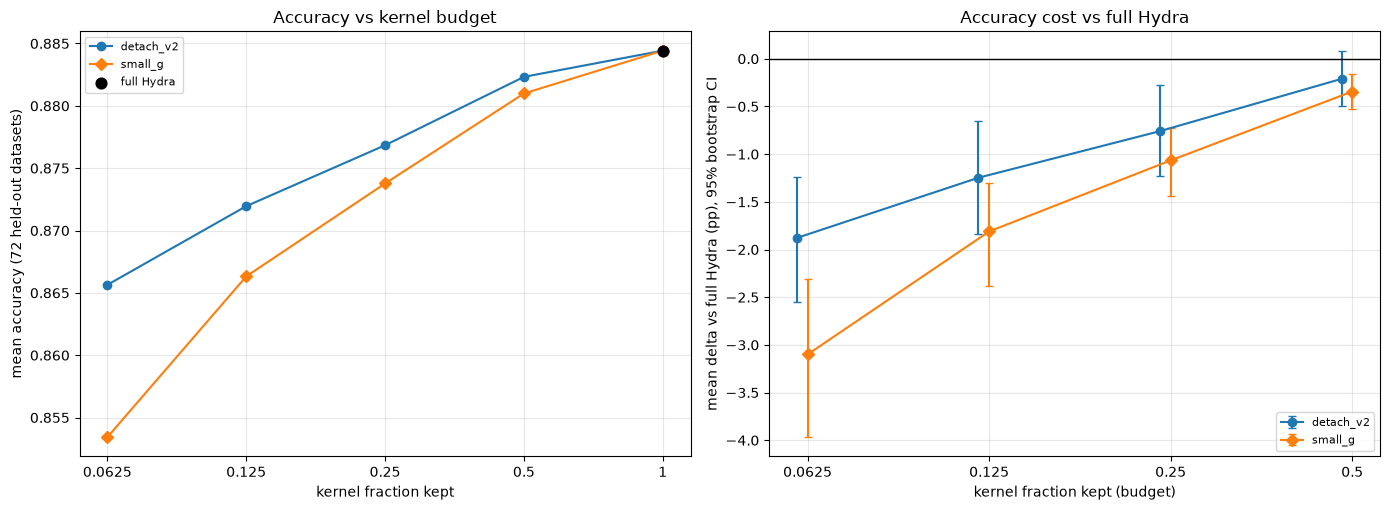

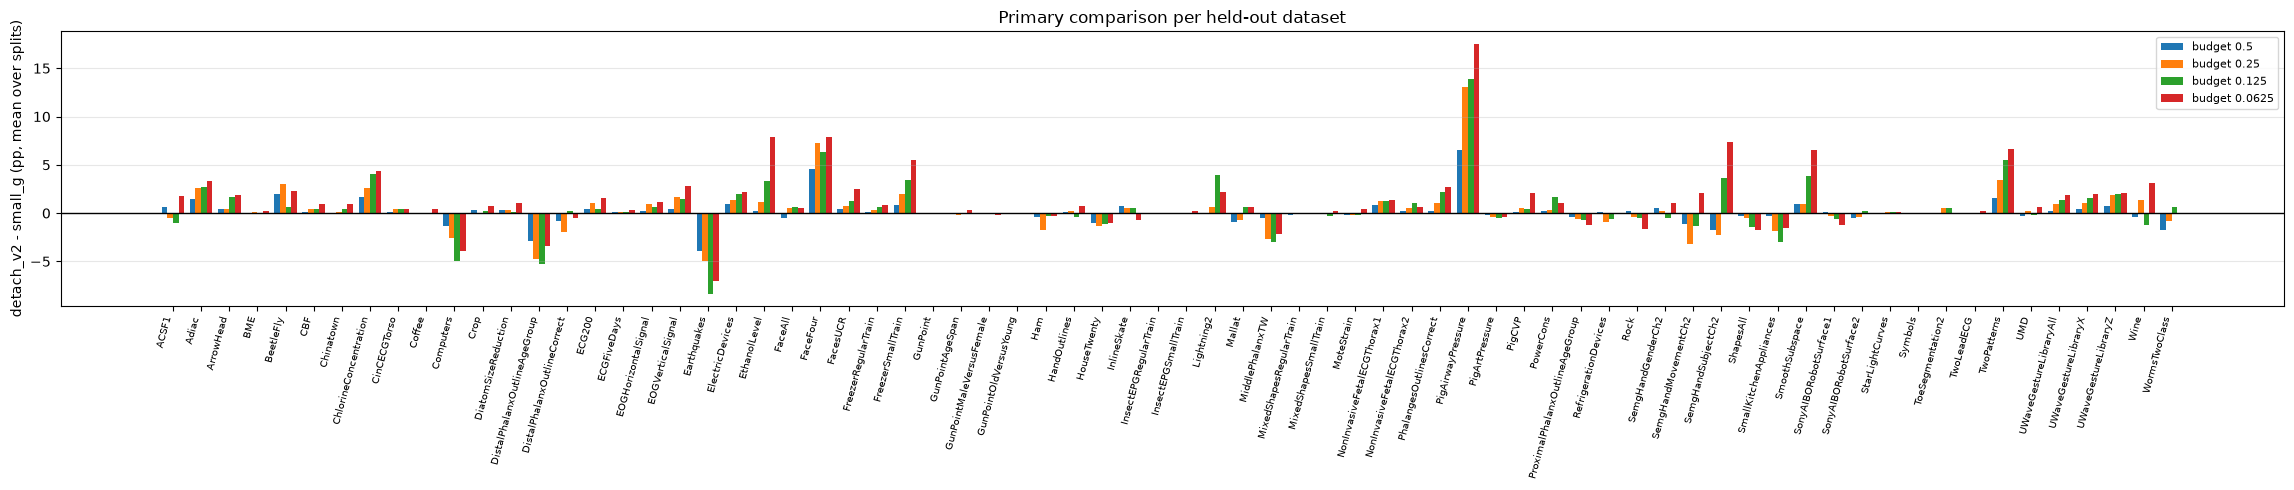

detach_v2: keep rate by relative dilation, relative to uniform (1.0 = small_g):


dil_bin,short,mid,long
budget,,,
0.0625,0.65,0.98,1.47
0.1250,0.69,1.00,1.41
0.2500,0.74,1.02,1.31
0.5000,0.82,1.03,1.20


detach_v2: share of kept groups on diff(X) (0.5 = uniform):


,mean,min,max
budget,,,
0.0625,0.347,0.000,0.860
0.1250,0.386,0.000,0.860
0.2500,0.413,0.004,0.835
0.5000,0.455,0.156,0.799


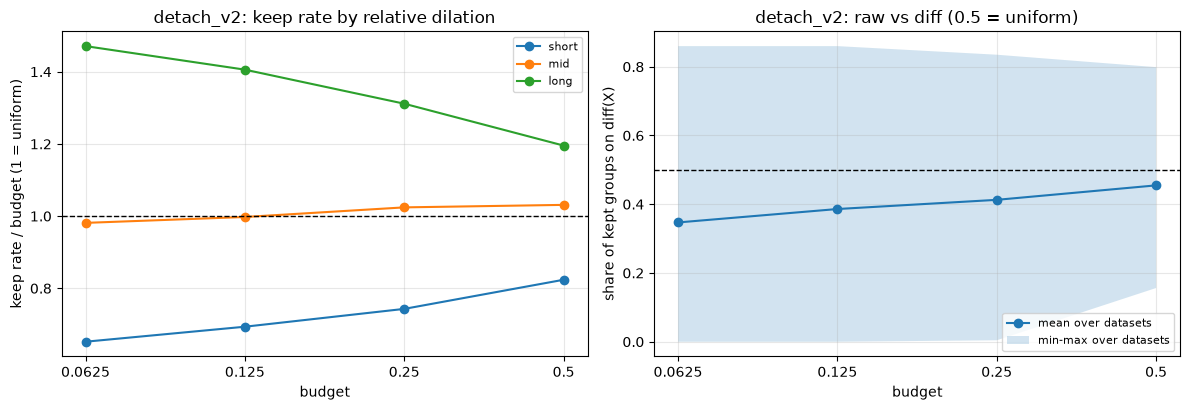

Block coverage (fraction of (dilation, input) blocks with >= 1 kept group), mean:


budget,0.0625,0.1250,0.2500,0.5000,1.0000
method,,,,,
detach_v2,0.691,0.84,0.939,0.989,NaN
full,NaN,NaN,NaN,NaN,1.0
full_author_grid,NaN,NaN,NaN,NaN,1.0
small_g,1.000,1.00,1.000,1.000,NaN


minimum over pairs:


budget,0.0625,0.1250,0.2500,0.5000
method,,,,
detach_v2,0.167,0.25,0.5,0.786


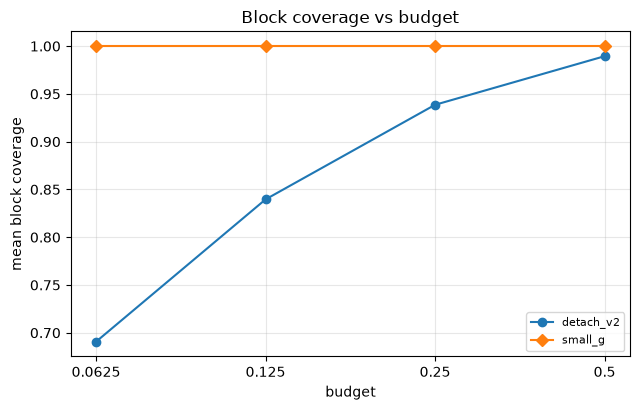

In [24]:
# ---- 8.6 Figures ----
markers = {"detach_v2": "o", "small_g": "D", "detach_v1": "s"}

# (a) mean accuracy vs kernel fraction, and delta vs full with 95% bootstrap CIs
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5.2))
for m in METHODS:
    ax1.plot([1.0] + BUDGETS, [FULL.mean()] + [acc_of(m, b).mean() for b in BUDGETS], marker=markers[m], label=m)
ax1.scatter([1.0], [FULL.mean()], color="black", zorder=5, s=60, label="full Hydra")
ax1.set_xscale("log"); ax1.set_xticks([1.0] + BUDGETS, ["1"] + [str(b) for b in BUDGETS]); ax1.minorticks_off()
ax1.set_xlabel("kernel fraction kept"); ax1.set_ylabel(f"mean accuracy ({len(DS_USED)} held-out datasets)")
ax1.set_title("Accuracy vs kernel budget"); ax1.grid(alpha=0.3); ax1.legend(fontsize=8)
for j, m in enumerate(METHODS):
    st = [compare(acc_of(m, b), FULL) for b in BUDGETS]
    xs = np.array(BUDGETS) * (1 + 0.04 * (j - 1))
    ax2.errorbar(xs, [s["mean_pp"] for s in st],
                 yerr=[[s["mean_pp"] - s["ci_lo"] for s in st], [s["ci_hi"] - s["mean_pp"] for s in st]],
                 marker=markers[m], capsize=3, label=m)
ax2.axhline(0, color="black", lw=1)
ax2.set_xscale("log"); ax2.set_xticks(BUDGETS, [str(b) for b in BUDGETS]); ax2.minorticks_off()
ax2.set_xlabel("kernel fraction kept (budget)"); ax2.set_ylabel("mean delta vs full Hydra (pp), 95% bootstrap CI")
ax2.set_title("Accuracy cost vs full Hydra"); ax2.grid(alpha=0.3); ax2.legend(fontsize=8)
fig.tight_layout()
fig.savefig(FIG_DIR / f"{FIG_PREFIX}accuracy_vs_budget.png", dpi=150, bbox_inches="tight")
plt.show()

# (b) per-dataset detach_v2 - small_g at the 4 budgets
fig, ax = plt.subplots(figsize=(max(10, 0.32 * len(DS_USED)), 5))
w = 0.2
for j, b in enumerate(BUDGETS):
    ax.bar(np.arange(len(DS_USED)) + (j - 1.5) * w, dsg[f"d_{b}"].to_numpy(), width=w, label=f"budget {b}")
ax.axhline(0, color="black", lw=1)
ax.set_xticks(np.arange(len(DS_USED)), DS_USED, rotation=75, ha="right", fontsize=7)
ax.set_ylabel("detach_v2 - small_g (pp, mean over splits)"); ax.set_title("Primary comparison per held-out dataset")
ax.grid(axis="y", alpha=0.3); ax.legend(fontsize=8)
fig.tight_layout()
fig.savefig(FIG_DIR / f"{FIG_PREFIX}per_dataset_delta.png", dpi=150, bbox_inches="tight")
plt.show()

# (c) detach_v2 keep rate by relative dilation (short / mid / long) and the share on diff(X), per budget
kd = kept_df[kept_df["dataset"].isin(DS_USED) & (kept_df["method"] == "detach_v2")].copy()
nd = kd.groupby("dataset")["dilation_index"].transform("max") + 1
kd["rel_dilation"] = np.where(nd > 1, kd["dilation_index"] / (nd - 1).clip(lower=1), 0.0)
kd["dil_bin"] = pd.cut(kd["rel_dilation"], [-0.01, 1 / 3, 2 / 3, 1.01], labels=["short", "mid", "long"])
rate = (kd.groupby(["dataset", "resample", "budget", "dil_bin"], observed=True)["kept"].mean()
        .groupby(["dataset", "budget", "dil_bin"], observed=True).mean().reset_index())
rate["rel_rate"] = rate["kept"] / rate["budget"]
dil_share = rate.groupby(["budget", "dil_bin"], observed=True)["rel_rate"].mean().unstack()
diff_share = (kd[kd["kept"]].groupby(["dataset", "resample", "budget"])["diff_index"].mean()
              .groupby(["dataset", "budget"]).mean().groupby("budget").agg(["mean", "min", "max"]))
print("detach_v2: keep rate by relative dilation, relative to uniform (1.0 = small_g):")
display(dil_share.round(2))
print("detach_v2: share of kept groups on diff(X) (0.5 = uniform):")
display(diff_share.round(3))
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4.2))
for bin_ in dil_share.columns:
    ax1.plot(dil_share.index, dil_share[bin_], marker="o", label=str(bin_))
ax1.axhline(1, color="black", lw=1, ls="--")
ax1.set_xscale("log"); ax1.set_xticks(BUDGETS, [str(b) for b in BUDGETS]); ax1.minorticks_off()
ax1.set_xlabel("budget"); ax1.set_ylabel("keep rate / budget (1 = uniform)")
ax1.set_title("detach_v2: keep rate by relative dilation"); ax1.grid(alpha=0.3); ax1.legend(fontsize=8)
ax2.plot(diff_share.index, diff_share["mean"], marker="o", label="mean over datasets")
ax2.fill_between(diff_share.index, diff_share["min"], diff_share["max"], alpha=0.2, label="min-max over datasets")
ax2.axhline(0.5, color="black", lw=1, ls="--")
ax2.set_xscale("log"); ax2.set_xticks(BUDGETS, [str(b) for b in BUDGETS]); ax2.minorticks_off()
ax2.set_xlabel("budget"); ax2.set_ylabel("share of kept groups on diff(X)")
ax2.set_title("detach_v2: raw vs diff (0.5 = uniform)"); ax2.grid(alpha=0.3); ax2.legend(fontsize=8)
fig.tight_layout()
fig.savefig(FIG_DIR / f"{FIG_PREFIX}kept_structure.png", dpi=150, bbox_inches="tight")
plt.show()

# (d) block coverage vs budget
cov = runs.groupby(["method", "budget"])["block_coverage"].mean().unstack()
min_cov = runs[runs["method"].isin(["detach_v2", "detach_v1"])].groupby(["method", "budget"])["block_coverage"].min().unstack()
print("Block coverage (fraction of (dilation, input) blocks with >= 1 kept group), mean:")
display(cov.round(3))
print("minimum over pairs:")
display(min_cov.round(3))
fig, ax = plt.subplots(figsize=(6.5, 4.2))
for m in METHODS:
    ax.plot(BUDGETS, [cov.loc[m, b] for b in BUDGETS], marker=markers[m], label=m)
ax.set_xscale("log"); ax.set_xticks(BUDGETS, [str(b) for b in BUDGETS]); ax.minorticks_off()
ax.set_xlabel("budget"); ax.set_ylabel("mean block coverage"); ax.set_title("Block coverage vs budget")
ax.grid(alpha=0.3); ax.legend(fontsize=8)
fig.tight_layout()
fig.savefig(FIG_DIR / f"{FIG_PREFIX}block_coverage.png", dpi=150, bbox_inches="tight")
plt.show()

In [25]:
# ---- 8.7 Breakdowns of delta(detach_v2 - small_g), pp (tables only) ----
bd = dsg.join(META)
bins = {
    "n_train": (bd["n_train"], [0, 100, 500, np.inf], ["<=100", "101-500", ">500"]),
    "length": (bd["length"], [0, 200, 500, np.inf], ["<=200", "201-500", ">500"]),
    "n_classes": (bd["n_classes"], [0, 2, 10, np.inf], ["2", "3-10", ">10"]),
}
for name, (col, edges, labels) in bins.items():
    grp = pd.cut(col, edges, labels=labels)
    t = bd[[f"d_{b}" for b in BUDGETS]].groupby(grp, observed=False).mean()
    t.insert(0, "n_datasets", grp.value_counts().reindex(labels).fillna(0).astype(int))
    print(f"delta(detach_v2 - small_g) in pp by {name}:")
    display(t.round(2))

print("Checks logged in this session:")
for name, res in CHECKS:
    print(f"  {res}: {name}")

delta(detach_v2 - small_g) in pp by n_train:


,n_datasets,d_0.5,d_0.25,d_0.125,d_0.0625
n_train,,,,,
<=100,30,0.24,0.47,0.49,0.93
101-500,27,-0.07,-0.11,0.23,1.22
>500,15,0.30,0.73,1.30,1.81


delta(detach_v2 - small_g) in pp by length:


,n_datasets,d_0.5,d_0.25,d_0.125,d_0.0625
length,,,,,
<=200,28,0.08,0.16,0.58,0.97
201-500,12,0.54,1.09,1.22,2.03
>500,32,0.02,0.14,0.30,1.14


delta(detach_v2 - small_g) in pp by n_classes:


,n_datasets,d_0.5,d_0.25,d_0.125,d_0.0625
n_classes,,,,,
2,28,-0.20,-0.13,-0.09,0.33
3-10,32,0.18,0.15,0.67,1.50
>10,12,0.79,1.74,1.80,2.54


Checks logged in this session:
  PASS: official Hydra: divisor = 2, h = g//2, groups = num_dilations*g, dilations independent of g
  PASS: detach_v2_path and detach_path take training arrays only (v2 parameters: ['Xtr_scaled', 'ytr', 'group_cols', 'budgets', 'B', 'frac', 'alphas', 'seed_base'])
  PASS: dataset lists: 112 in the authors' CSV = 40 development + 72 held-out (disjoint)
  PASS: pilot Test 1 (all groups kept == official) on ECG200 + Beef
  PASS: pilot Tests 2+3 (random masks == kept columns; counts) on ECG200 + Beef
  PASS: pilot Test 4 (SparseScaler subset) on ECG200 + Beef
  PASS: v2 generalises v1: B = 1, frac = 1.0 gives the same kept masks as detach_path (ECG200, Beef)
  PASS: stratified subsampler: every class present, deterministic per seed, sizes max(1, round(frac*n_c))
  PASS: budget sizes: v2 keeps round(b*G) groups = num_dilations*g' of small_g (ECG200, path 0.6s)
  PASS: rebuild equivalence: PrunedHydra(v2 mask @ 0.25) == full features[:, kept_columns] (ECG200 tr